> **In this repository.** Baselines: a one-vs-rest logistic regression on the frozen features of each pretrained backbone, scored on `val.csv` with the same metrics as the fine-tuning runs. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# Baseline: one-vs-all logistic regression on frozen embeddings

One baseline model for each pretrained model in the experimental design. Each extracts features from a pretrained backbone, and a one-vs-all logistic regression over the 40 invasive species is fit on the pooled embeddings of the training images. `not_invasive` is predicted when no class probability reaches the threshold tuned on validation, exactly as in the fine-tuning notebooks.

Metrics are directly comparable to other models and written to `modeling_runs/logreg_<backbone>/00_baseline/` (`config.json`, `history.csv` for information about the regularization tuning, `best.joblib` instead of `best.pt`, `metrics_final.json`, `val_predictions.csv`, plots) plus a `decisions.json` that accepts the run. Then `18_final_model_comparison.ipynb` shows each baseline as a model next to the fine-tuned ones.

The notebook trains on `train.csv`, tunes and evaluates on `val.csv`, and **never touches `test.csv` or `test_unseen.csv`**.

## How the notebook is organized

* **Section 1** holds `BASE_CONFIG`: the input transform, the logistic-regression settings and the evaluation settings. A backbone cell can pass overrides, for example a different `backbone_kwargs`.
* **Sections 2, 3 and 4** (data, backbone adapters, metrics and plots) are copies of the corresponding cells of the fine-tuning notebooks and should stay identical to them.
* **Section 5** extracts features and fits the logistic regression: the inverse regularization strength `C` is swept over `C_grid`, each fit is evaluated on validation with its own tuned threshold, and the `C` with the best `select_metric` is kept. The sweep is saved as `history.csv`, one row per `C`, in place of the per-epoch history of a fine-tuning run.
* **Section 6** runs one baseline per backbone. Runs that already have results are shown, not repeated, unless `overwrite=True`.

## Task encoding (from the design doc)

* 40 one-vs-all logistic regressions, one per invasive species; `not_invasive` rows are negatives for every one of them (the all-zero target of the fine-tuning notebooks).
* Binary "is invasive" = `max_c p_c >= threshold`; species = `argmax_c` when invasive, else `not_invasive`.
* The threshold is tuned on the validation set to maximize **macro-F1 over the 40 invasive species** (the primary validation metric). All thresholded metrics use that fixed threshold.
* Primary KPI: top-1 accuracy over all 41 labels.

## Features

Train and validation images go through the same deterministic transform (`Resize(val_resize)`, `CenterCrop(image_size)`, the backbone's normalization), with no augmentation. Embeddings are standardised per dimension with a `StandardScaler` fit on train. The final evaluation averages the probabilities of each validation image and its mirror image, like the TTA of the fine-tuning notebooks.

## 0. Environment

In [ ]:
import importlib.util, os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")

# Install what is missing (Colab ships torch/torchvision/sklearn/pandas/matplotlib already).
_required = {"torchmetrics": "torchmetrics", "timm": "timm", "huggingface_hub": "huggingface_hub",
             "transformers": "transformers>=4.57.3", "open_clip": "open_clip_torch"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# DINOv3 needs transformers >= 4.57.3 (PlantNet's own requirements.txt). Upgrade if the class is absent.
import transformers
if importlib.util.find_spec("transformers.models.dinov3_vit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.57.3"])
    print("transformers upgraded; RESTART THE RUNTIME and run again.")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import copy, datetime, json, math, random, re, shutil, time, warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.transforms import v2
import torchmetrics
from torchmetrics.classification import MulticlassF1Score, MulticlassAccuracy, MulticlassConfusionMatrix
from tqdm.auto import tqdm
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
import joblib

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
print(f"torch {torch.__version__} | transformers {transformers.__version__} | torchmetrics {torchmetrics.__version__}")
print(f"device: {DEVICE} | mixed-precision dtype: {AMP_DTYPE if DEVICE.type == 'cuda' else 'disabled (CPU)'}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

# Plot style shared by every notebook so figures are comparable across models.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
C_BLUE, C_ORANGE, C_GRAY = "#2a78d6", "#eb6834", "#9a9995"

def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch 2.11.0+cpu | transformers 5.22.0 | torchmetrics 1.9.0
device: cpu | mixed-precision dtype: disabled (CPU)


## 1. Configuration

`BASE_CONFIG` applies to every backbone. A backbone cell in Section 6 can pass a `dict` of overrides (same keys), which is recorded in that run's `config.json`.

In [ ]:
# Leave both as None to use the Team Drive path on Colab or the repo-relative path locally.
DATA_ROOT_OVERRIDE = None                    # e.g. "/path/to/downloaded_data/inat_dataset_final"
RUNS_DIR_OVERRIDE = None                     # e.g. "/path/to/modeling_runs"; default: <repo root>/modeling_runs

BASE_CONFIG = {
    # --- input: the deterministic eval transform of the fine-tuning notebooks, used for train and val alike ---
    "image_size": 224,
    "val_resize": 256,                        # Resize(shorter side) then CenterCrop(image_size)
    "batch_size": 128,                        # feature extraction only (no backward pass); reduce if the GPU runs out of memory
    "num_workers": 2,
    "amp": True,                              # mixed precision for the feature extraction
    "backbone_kwargs": {},                    # adapter defaults: DINOv3 "cls" pooling, BioCLIP projected features, no drop path
    # --- one-vs-all logistic regression over the invasive classes ---
    "standardize": True,                      # StandardScaler fit on the train embeddings
    "C_grid": [1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],   # inverse L2 strength; chosen on validation
    "class_weight": None,                     # None = plain logistic loss (like the fine-tuned baseline's plain BCE); or "balanced"
    "max_iter": 5000,                         # lbfgs iterations per binary problem
    # --- evaluation ---
    "threshold_grid": [round(t, 3) for t in np.linspace(0.01, 0.99, 99)],
    "select_metric": "macro_f1_invasive",     # C selection + threshold tuning target
    "tta_hflip": True,                        # final evaluation averages the probabilities of each val image and its mirror
    # --- bookkeeping ---
    "seed": 42,
}


## 2. Paths and data

The dataset folder is `DATA_ROOT_OVERRIDE` if set, else the Team Drive path on Colab, else the repo-relative path. Only `train.csv` and `val.csv` are read. The last cell of this section decodes every image once into RAM as a center crop (about 1.6 GB); every backbone extracts its features from that cache, so the images are read from Drive a single time per kernel.

In [ ]:
_candidates = [DATA_ROOT_OVERRIDE,
               "/content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "/content/drive/Shareddrives/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "../../downloaded_data/inat_dataset_final", "downloaded_data/inat_dataset_final"]
DATA_ROOT = next((Path(p) for p in _candidates if p and (Path(p) / "train.csv").exists()), None)
assert DATA_ROOT is not None, f"dataset folder not found; tried {_candidates}"
RUNS_DIR = Path(RUNS_DIR_OVERRIDE) if RUNS_DIR_OVERRIDE else DATA_ROOT.parent.parent / "modeling_runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_ROOT:", DATA_ROOT.resolve()); print("RUNS_DIR:", RUNS_DIR.resolve())

NONE_LABEL = "not_invasive"
train_df = pd.read_csv(DATA_ROOT / "train.csv")
val_df = pd.read_csv(DATA_ROOT / "val.csv")

INVASIVE_CLASSES = sorted(c for c in train_df["label"].unique() if c != NONE_LABEL)
N_INVASIVE = len(INVASIVE_CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(INVASIVE_CLASSES)}
CLASS_TO_IDX[NONE_LABEL] = N_INVASIVE                   # index N_INVASIVE = not_invasive (no logit, only a target)
ALL_LABELS = INVASIVE_CLASSES + [NONE_LABEL]            # 41 names in index order
assert set(val_df["label"]) <= set(ALL_LABELS), "val has labels that train does not"
assert not set(train_df["observer_id"]) & set(val_df["observer_id"]), "observer leakage between train and val"

for name, df in (("train", train_df), ("val", val_df)):
    df["y"] = df["label"].map(CLASS_TO_IDX)
    print(f"{name}: {len(df):>5} rows | {df['invasive'].sum():>4} invasive | {(~df['invasive']).sum():>4} {NONE_LABEL} | "
          f"{df.loc[df['invasive'], 'label'].nunique()} invasive classes, {df['scientific_name'].nunique()} species")
print(f"{N_INVASIVE} invasive classes -> {N_INVASIVE} logits; '{NONE_LABEL}' is the all-zero target (index {N_INVASIVE})")

DATA_ROOT: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final
RUNS_DIR: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs
train:  7342 rows | 1186 invasive | 6156 not_invasive | 40 invasive classes, 441 species
val:  3228 rows |  982 invasive | 2246 not_invasive | 40 invasive classes, 441 species
40 invasive classes -> 40 logits; 'not_invasive' is the all-zero target (index 40)


In [ ]:
# Check which image files exist (the download may have gaps; see download_failures.csv).
_failures_file = DATA_ROOT / "download_failures.csv"
if _failures_file.exists():
    try:
        _f = pd.read_csv(_failures_file)
        print(f"download_failures.csv: {len(_f)} rows")
    except pd.errors.EmptyDataError:                 # the download cell writes an empty file when nothing failed
        print("download_failures.csv exists but is empty: no failed downloads")

for name, df in (("train", train_df), ("val", val_df)):
    df["exists"] = df["image_path"].map(lambda p: (DATA_ROOT / p).is_file())
    n_missing = (~df["exists"]).sum()
    if n_missing:
        missing_by_class = df.loc[~df["exists"], "label"].value_counts()
        print(f"{name}: {n_missing} rows without an image file (dropped). Worst classes:\n{missing_by_class.head(8).to_string()}")
    else:
        print(f"{name}: all {len(df)} image files present")
train_df = train_df[train_df["exists"]].reset_index(drop=True)
val_df = val_df[val_df["exists"]].reset_index(drop=True)
assert len(train_df) and len(val_df), "no images found under DATA_ROOT; is Drive mounted / are the images downloaded?"

download_failures.csv exists but is empty: no failed downloads
train: all 7342 image files present
val: all 3228 image files present


In [ ]:
# Decode every train/val image ONCE into RAM as uint8 center crops: Resize(val_resize) -> CenterCrop(image_size).
# Reading 10k small files from a mounted Drive is slow (tens of minutes), so it is done a single time per kernel and every
# backbone below extracts its features from these tensors. Nothing is written to disk.


class _Decode(Dataset):
    # one-off decode + deterministic transform; wrapped in a DataLoader only to use several worker processes
    def __init__(self, paths, tf):
        self.paths, self.tf = list(paths), tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = ImageOps.exif_transpose(Image.open(DATA_ROOT / self.paths[i])).convert("RGB")
        return T.functional.pil_to_tensor(self.tf(img))                  # uint8, C x H x W


def decode_all(paths, tf, desc):
    dl = DataLoader(_Decode(paths, tf), batch_size=None, num_workers=BASE_CONFIG["num_workers"],
                    generator=torch.Generator().manual_seed(0))                                     # do not touch the global RNG
    return torch.stack([t for t in tqdm(dl, total=len(paths), desc=desc, unit="img", leave=False)])


EVAL_TF = T.Compose([T.Resize(BASE_CONFIG["val_resize"]), T.CenterCrop(BASE_CONFIG["image_size"])])
t0 = time.time()
TRAIN_IMAGES = decode_all(train_df["image_path"], EVAL_TF, "decoding train images")
VAL_IMAGES = decode_all(val_df["image_path"], EVAL_TF, "decoding val images")
print(f"image cache: {len(TRAIN_IMAGES)} train + {len(VAL_IMAGES)} val center crops of {BASE_CONFIG['image_size']}x{BASE_CONFIG['image_size']} = "
      f"{(TRAIN_IMAGES.numel() + VAL_IMAGES.numel()) / 2**30:.2f} GB in RAM ({time.time() - t0:.0f}s)")


decoding train images:   0%|          | 0/7342 [00:00<?, ?img/s]

decoding val images:   0%|          | 0/3228 [00:00<?, ?img/s]

image cache: 7342 train + 3228 val centre crops of 224x224 = 1.48 GB in RAM (1330s)


## 3. Backbone adapters

A backbone adapter returns a `BackboneSpec`: an `nn.Module` whose `forward(x)` maps a normalized image batch to the **native pooled feature vector**, plus the feature dimension and the normalization constants of the checkpoint. Identical to the fine-tuning notebooks; here the backbone stays frozen and its pooled features feed the logistic regression.

Adapters read `cfg["backbone_kwargs"]` for model-specific options. Implemented: ResNet-50, ConvNeXt-Tiny, DINOv3 ViT-S/16, PlantNet DINOv3 ViT-S/16, and SigLIP 2 ViT-B/16. `layer_decay` understands the block naming of all of them (`layer.N`, `blocks.N`, `resblocks.N`).

In [ ]:
@dataclass
class BackboneSpec:
    module: nn.Module          # forward(x) -> (B, feat_dim) pooled features
    feat_dim: int
    mean: tuple                # normalization of the checkpoint
    std: tuple
    notes: str = ""

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class HFPooledBackbone(nn.Module):
    # Wraps a HF vision model. pooling="cls": .pooler_output (DINOv3: final-normed CLS token).
    # pooling="cls+patchmean": CLS concatenated with the mean of the patch tokens (skips CLS + register tokens).
    def __init__(self, hf_model, pooling="cls", n_prefix_tokens=1):
        super().__init__(); self.m = hf_model; self.pooling = pooling; self.n_prefix = n_prefix_tokens
        assert pooling in ("cls", "cls+patchmean"), pooling
    def forward(self, x):
        out = self.m(pixel_values=x)
        if self.pooling == "cls":
            return out.pooler_output
        return torch.cat([out.pooler_output, out.last_hidden_state[:, self.n_prefix:].mean(1)], dim=1)


def build_plantnet_dinov3_vits(cfg) -> BackboneSpec:
    # PlantNet/plantnet-300k-v2-vits: DINOv3 ViT-S/16 encoder + 1000-way head in model.pth.
    # We rebuild the encoder architecture from config (ViT-S/16 with 4 register tokens; verified to load with
    # strict=True) so the gated facebook/dinov3-* weights are NOT needed; the encoder weights come from model.pth.
    # The 1000-class Pl@ntNet head is discarded.
    from huggingface_hub import snapshot_download
    from transformers import DINOv3ViTConfig, DINOv3ViTModel
    repo = snapshot_download("PlantNet/plantnet-300k-v2-vits", allow_patterns=["model.pth", "plantnet_config.json"])
    pn_cfg = json.load(open(Path(repo) / "plantnet_config.json"))
    ckpt = torch.load(Path(repo) / "model.pth", map_location="cpu", weights_only=True)
    bk = cfg.get("backbone_kwargs", {})
    pooling, drop_path = bk.get("pooling", "cls"), bk.get("drop_path_rate", 0.0)
    encoder = DINOv3ViTModel(DINOv3ViTConfig(hidden_size=384, num_hidden_layers=12, num_attention_heads=6,
                                             intermediate_size=1536, patch_size=16, num_register_tokens=4,
                                             image_size=cfg["image_size"], drop_path_rate=drop_path))
    encoder.load_state_dict(ckpt["encoder"], strict=True)
    feat_dim = pn_cfg["embedding_dim"] * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(encoder, pooling, n_prefix_tokens=1 + 4), feat_dim, tuple(pn_cfg["image_mean"]),
                        tuple(pn_cfg["image_std"]),
                        notes=f"PlantNet-300K-v2 fine-tuned DINOv3 ViT-S/16; PlantNet mean/std; pooling={pooling}, drop_path={drop_path}")


def build_dinov3_vits16(cfg) -> BackboneSpec:
    # Plain DINOv3 ViT-S/16 (self-supervised, LVD-1689M). Gated: accept the license on HF and `huggingface-cli login`.
    from transformers import AutoModel
    enc = AutoModel.from_pretrained("facebook/dinov3-vits16-pretrain-lvd1689m")
    pooling = cfg.get("backbone_kwargs", {}).get("pooling", "cls")
    feat_dim = enc.config.hidden_size * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(enc, pooling, 1 + enc.config.num_register_tokens), feat_dim, IMAGENET_MEAN, IMAGENET_STD,
                        notes=f"DINOv3 ViT-S/16, ImageNet mean/std, pooling={pooling}")


class TimmBackbone(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x)                       # num_classes=0 -> pooled features


def build_timm(timm_name):
    # Any timm checkpoint, e.g. "resnet50.a1_in1k", "convnext_tiny.fb_in22k_ft_in1k",
    # "vit_base_patch16_siglip_224.v2_webli" (the SigLIP 2 ViT-B/16 image tower with its attention-pooling head, 768-d).
    # backbone_kwargs["drop_path_rate"] is passed through when set (ViTs, ConvNeXt; ResNets ignore it).
    def _build(cfg) -> BackboneSpec:
        import timm
        drop_path = cfg.get("backbone_kwargs", {}).get("drop_path_rate", 0.0)
        kw = {"drop_path_rate": drop_path} if drop_path else {}
        m = timm.create_model(timm_name, pretrained=True, num_classes=0, **kw)   # drops the pretraining head, keeps the pooling
        dc = timm.data.resolve_data_config({}, model=m)
        return BackboneSpec(TimmBackbone(m), m.num_features, tuple(dc["mean"]), tuple(dc["std"]),
                            notes=f"timm {timm_name}, pool={getattr(m, 'global_pool', '?')}, drop_path={drop_path}")
    return _build

BACKBONE_REGISTRY = {
    "plantnet_dinov3_vits": build_plantnet_dinov3_vits,
    "dinov3_vits16": build_dinov3_vits16,
    "resnet50": build_timm("resnet50.a1_in1k"),
    "convnext_tiny": build_timm("convnext_tiny.fb_in22k_ft_in1k"),
    "siglip2_base": build_timm("vit_base_patch16_siglip_224.v2_webli"),      # SigLIP 2 ViT-B/16, 93M params, 768-d MAP features
}
print("registered backbones:", list(BACKBONE_REGISTRY))


registered backbones: ['plantnet_dinov3_vits', 'dinov3_vits16', 'resnet18', 'resnet50', 'convnext_tiny', 'bioclip', 'bioclip2', 'siglip2_base']


## 4. Metrics (identical in every model notebook)

Inputs: `probs` of shape `(N, N_INVASIVE)` = the one-vs-all probabilities, and `y` in `0..N_INVASIVE` (`N_INVASIVE` = `not_invasive`).

| metric | definition |
|---|---|
| `macro_ap_invasive` | mean over the invasive classes of average precision (one-vs-rest, threshold-free) |
| `top1_recall_invasive`, `top3_recall_invasive` | among rows whose true label is invasive: is the true class the top-1 / within the top-3 ranked logits (threshold-free) |
| `threshold` | value of `t` on `threshold_grid` maximizing `macro_f1_invasive` on the validation set |
| `macro_f1_invasive` | **primary validation metric**: per-class F1 of the 41-way prediction (`argmax` if `max prob >= t` else `not_invasive`), averaged over the invasive classes only, computed on all rows |
| `top1_acc_all` | **primary KPI**: accuracy of the 41-way prediction over all rows |
| `bin_precision_invasive`, `bin_recall_invasive`, `bin_f1_invasive`, `bin_ap_invasive`, `bin_auroc_invasive` | binary "invasive vs not" with score `max prob` and threshold `t` |
| `noninv_precision`, `noninv_recall`, `noninv_auroc` | the same binary problem seen from the `not_invasive` side (positive = not invasive, score `1 - max prob`) |
| `per_class_f1`, `per_class_ap`, `confusion_matrix` | arrays for the plots and for `metrics_final.json` |

In [ ]:
def predict_not_invasive(probs: np.ndarray, t: float) -> np.ndarray:
    # Species when the strongest invasive probability clears t, otherwise not_invasive.
    pred = probs.argmax(1)
    pred[probs.max(1) < t] = N_INVASIVE
    return pred


def macro_f1_invasive(y: np.ndarray, pred: np.ndarray) -> float:
    f1 = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y))
    return float(f1[:N_INVASIVE].mean())


def tune_threshold(probs, y, grid):
    # Sweep the grid; return the best t plus the full sweep for plotting.
    sweep = pd.DataFrame({"threshold": grid})
    sweep["macro_f1_invasive"] = [macro_f1_invasive(y, predict_not_invasive(probs, t)) for t in grid]
    sweep["top1_acc_all"] = [float((predict_not_invasive(probs, t) == y).mean()) for t in grid]
    best = sweep.loc[sweep["macro_f1_invasive"].idxmax()]
    return float(best["threshold"]), sweep


def compute_metrics(probs: np.ndarray, y: np.ndarray, threshold: float | None, grid) -> dict:
    probs = np.asarray(probs, dtype=np.float64); y = np.asarray(y)
    is_inv = y < N_INVASIVE
    onehot = np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]              # (N, N_INVASIVE) binary targets

    m = {}
    # threshold-free, ranking metrics over the invasive classes
    per_class_ap = np.array([average_precision_score(onehot[:, c], probs[:, c]) if onehot[:, c].any() else np.nan
                             for c in range(N_INVASIVE)])
    m["macro_ap_invasive"] = float(np.nanmean(per_class_ap))
    if is_inv.any():
        rank = (-probs[is_inv]).argsort(1)
        m["top1_recall_invasive"] = float((rank[:, 0] == y[is_inv]).mean())
        m["top3_recall_invasive"] = float((rank[:, :3] == y[is_inv, None]).any(1).mean())
    # threshold
    sweep = None
    if threshold is None:
        threshold, sweep = tune_threshold(probs, y, grid)
    m["threshold"] = float(threshold)
    pred = predict_not_invasive(probs, threshold)
    # 41-way metrics at the fixed threshold
    f1_per_class = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y)).numpy()
    m["macro_f1_invasive"] = float(f1_per_class[:N_INVASIVE].mean())
    m["macro_f1_all41"] = float(f1_per_class.mean())
    m["top1_acc_all"] = float(MulticlassAccuracy(num_classes=N_INVASIVE + 1, average="micro")(torch.as_tensor(pred), torch.as_tensor(y)))
    # binary invasive detection
    score_inv = probs.max(1); pred_inv = pred < N_INVASIVE
    m["bin_precision_invasive"] = precision_score(is_inv, pred_inv, zero_division=0)
    m["bin_recall_invasive"] = recall_score(is_inv, pred_inv, zero_division=0)
    m["bin_f1_invasive"] = f1_score(is_inv, pred_inv, zero_division=0)
    m["bin_ap_invasive"] = average_precision_score(is_inv, score_inv)
    m["bin_auroc_invasive"] = roc_auc_score(is_inv, score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # the not_invasive side
    m["noninv_precision"] = precision_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_recall"] = recall_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_auroc"] = roc_auc_score(~is_inv, 1 - score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # arrays
    m["per_class_f1"] = f1_per_class.tolist()
    m["per_class_ap"] = per_class_ap.tolist()
    m["confusion_matrix"] = MulticlassConfusionMatrix(num_classes=N_INVASIVE + 1)(torch.as_tensor(pred), torch.as_tensor(y)).numpy().tolist()
    m["_sweep"] = sweep; m["_pred"] = pred
    return m

SCALAR_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
                  "threshold", "bin_precision_invasive", "bin_recall_invasive", "bin_f1_invasive", "bin_ap_invasive",
                  "bin_auroc_invasive", "noninv_precision", "noninv_recall", "noninv_auroc", "macro_f1_all41"]
KEY_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
               "bin_precision_invasive", "bin_recall_invasive", "bin_auroc_invasive", "noninv_auroc", "threshold"]

def scalars(m: dict) -> dict:
    return {k: m[k] for k in SCALAR_METRICS if k in m}

### 4b. Plots

The same plots as the fine-tuning notebooks; the training curves are replaced by the sweep over `C`.

In [ ]:
def plot_training_curves(hist: pd.DataFrame, out_dir: Path, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    ax = axes[0]; ax.plot(hist["epoch"], hist["train_loss"], color=C_BLUE, lw=2, label="train loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title("training loss")
    ax = axes[1]; ax.plot(hist["epoch"], hist["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive, primary)")
    ax.plot(hist["epoch"], hist["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41 classes, KPI)")
    ax.plot(hist["epoch"], hist["macro_ap_invasive"], color=C_GRAY, lw=1.5, label="macro-AP (invasive)")
    ax.set_ylim(0, 1.15); ax.set_xlabel("epoch"); ax.set_title("validation metrics"); ax.legend(fontsize=7, loc="upper left", ncol=3, frameon=False)
    ax = axes[2]; ax.plot(hist["epoch"], hist["lr_head"], color=C_ORANGE, lw=2, label="head LR")
    ax.plot(hist["epoch"], hist["lr_backbone"], color=C_BLUE, lw=2, label="backbone LR")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title("learning rate (end of epoch; top block if layer decay)"); ax.legend(fontsize=7)
    for a in axes:
        if "frozen_epochs" in hist.attrs and hist.attrs["frozen_epochs"]:
            a.axvline(hist.attrs["frozen_epochs"] + 0.5, color=C_GRAY, ls="--", lw=1)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "training_curves.png"); plt.show()


def plot_threshold_sweep(sweep: pd.DataFrame, t: float, out_dir: Path, title=""):
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(sweep["threshold"], sweep["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive)")
    ax.plot(sweep["threshold"], sweep["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41)")
    ax.axvline(t, color=C_GRAY, ls="--", lw=1); ax.text(t, 0.02, f" t = {t:.2f}", fontsize=8)
    ax.set_xlabel("invasive threshold on max class probability"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
    ax.set_title(title or "threshold sweep (validation)", fontsize=8); fig.tight_layout(); fig.savefig(out_dir / "threshold_sweep.png"); plt.show()


def plot_pr_roc(probs, y, m: dict, out_dir: Path, title=""):
    is_inv = y < N_INVASIVE; score = probs.max(1); t = m["threshold"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    # binary PR curve: invasive vs not
    p, r, th = precision_recall_curve(is_inv, score)
    ax = axes[0]; ax.plot(r, p, color=C_BLUE, lw=2)
    ax.scatter([m["bin_recall_invasive"]], [m["bin_precision_invasive"]], color=C_ORANGE, s=40, zorder=3, label=f"operating point, t={t:.2f}")
    ax.axhline(is_inv.mean(), color=C_GRAY, ls=":", lw=1, label=f"prevalence {is_inv.mean():.2f}")
    ax.set_xlabel("recall (invasive)"); ax.set_ylabel("precision (invasive)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"binary invasive detection: AP = {m['bin_ap_invasive']:.3f}"); ax.legend(fontsize=7, loc="lower left")
    # per-class PR curves
    ax = axes[1]
    for c in range(N_INVASIVE):
        yc = (y == c)
        if yc.any():
            pc, rc, _ = precision_recall_curve(yc, probs[:, c]); ax.plot(rc, pc, color=C_BLUE, alpha=0.25, lw=1)
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"per-class PR, {N_INVASIVE} invasive classes: macro-AP = {m['macro_ap_invasive']:.3f}")
    # ROC
    ax = axes[2]
    if 0 < is_inv.sum() < len(y):
        fpr, tpr, _ = roc_curve(is_inv, score); ax.plot(fpr, tpr, color=C_BLUE, lw=2)
        fpr_t = float((~is_inv & (score >= t)).sum() / max((~is_inv).sum(), 1))
        ax.scatter([fpr_t], [m["bin_recall_invasive"]], color=C_ORANGE, s=40, zorder=3)
    ax.plot([0, 1], [0, 1], color=C_GRAY, ls=":", lw=1)
    ax.set_xlabel("false-positive rate (not_invasive flagged)"); ax.set_ylabel("true-positive rate (invasive found)")
    ax.set_title(f"ROC: AUROC = {m['bin_auroc_invasive']:.3f}")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "pr_roc.png"); plt.show()


def plot_confusion(m: dict, out_dir: Path, title="", normalize=True):
    cm = np.array(m["confusion_matrix"], dtype=float)
    if normalize:
        cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(ALL_LABELS))); ax.set_yticks(range(len(ALL_LABELS)))
    ax.set_xticklabels(ALL_LABELS, rotation=90, fontsize=6); ax.set_yticklabels(ALL_LABELS, fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(title or ("confusion matrix, row-normalized (recall on the diagonal)" if normalize else "confusion matrix (counts)"))
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); fig.tight_layout(); fig.savefig(out_dir / "confusion_matrix.png"); plt.show()


def plot_per_class_f1(m: dict, out_dir: Path, support: pd.Series, title=""):
    f1 = pd.Series(m["per_class_f1"][:N_INVASIVE], index=INVASIVE_CLASSES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.22 * N_INVASIVE + 1.5))
    ax.barh(f1.index, f1.values, color=C_BLUE, height=0.7)
    for i, (name, v) in enumerate(f1.items()):
        ax.text(min(v + 0.01, 0.9), i, f"n={int(support.get(name, 0))}", va="center", fontsize=6, color="#52514e")
    ax.set_xlim(0, 1); ax.set_xlabel("F1 on validation (at the tuned threshold)"); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(title or f"per-class F1; macro-F1 (invasive) = {m['macro_f1_invasive']:.3f}")
    fig.tight_layout(); fig.savefig(out_dir / "per_class_f1.png"); plt.show()

## 5. Features and logistic regression

`extract_features` runs the frozen backbone over the cached centre crops (normalised with the backbone's own mean/std) and returns the pooled features. `fit_logreg` standardizes them and fits `OneVsRestClassifier(LogisticRegression(C))` on the multi-hot targets (40 binary problems; `not_invasive` rows are negatives for all of them). `run_baseline` sweeps `C_grid`, evaluates each fit on validation with its own tuned threshold, keeps the best `C` by `select_metric`, re-evaluates it with mirror-TTA, and writes every artifact under `RUNS_DIR/logreg_<backbone>/00_baseline/`.

In [ ]:
@torch.no_grad()
def extract_features(spec: BackboneSpec, images: torch.Tensor, cfg, hflip=False, desc="") -> np.ndarray:
    # images: uint8 (N, 3, H, W) centre crops -> (N, feat_dim) float32 pooled features of the frozen backbone.
    model = spec.module.to(DEVICE).eval()
    mean = torch.tensor(spec.mean, device=DEVICE).view(1, 3, 1, 1); std = torch.tensor(spec.std, device=DEVICE).view(1, 3, 1, 1)
    use_amp = cfg["amp"] and DEVICE.type == "cuda"
    out = []
    for i in tqdm(range(0, len(images), cfg["batch_size"]), desc=desc, leave=False, unit="batch"):
        x = images[i:i + cfg["batch_size"]].to(DEVICE, non_blocking=True).float().div_(255).sub_(mean).div_(std)
        if hflip:
            x = torch.flip(x, dims=[3])
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            f = model(x)
        out.append(f.float().cpu())
    return torch.cat(out).numpy()


def multi_hot(y: np.ndarray) -> np.ndarray:
    return np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]          # not_invasive rows are all-zero: negative for every class


def fit_logreg(X: np.ndarray, y: np.ndarray, C: float, cfg) -> dict:
    scaler = StandardScaler().fit(X) if cfg["standardize"] else None
    Xs = scaler.transform(X) if scaler is not None else X
    clf = OneVsRestClassifier(LogisticRegression(C=C, max_iter=cfg["max_iter"], class_weight=cfg["class_weight"]), n_jobs=-1)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        clf.fit(Xs, multi_hot(y))
        n_nonconverged = sum(issubclass(x.category, ConvergenceWarning) for x in w)
    return {"scaler": scaler, "clf": clf, "C": C, "n_nonconverged": n_nonconverged}


def predict_proba(model: dict, X: np.ndarray) -> np.ndarray:
    Xs = model["scaler"].transform(X) if model["scaler"] is not None else X
    return model["clf"].predict_proba(Xs)                     # (N, N_INVASIVE): independent one-vs-all probabilities


def bce(probs: np.ndarray, Y: np.ndarray) -> float:
    p = np.clip(probs, 1e-7, 1 - 1e-7)
    return float(-(Y * np.log(p) + (1 - Y) * np.log(1 - p)).mean())


def load_baseline(backbone: str) -> dict | None:
    f = RUNS_DIR / f"logreg_{backbone}" / "00_baseline" / "metrics_final.json"
    return json.load(open(f)) if f.exists() else None


def run_baseline(backbone: str, overrides: dict | None = None, overwrite=False, show_plots=True) -> dict:
    overrides = overrides or {}
    unknown = set(overrides) - set(BASE_CONFIG)
    assert not unknown, f"unknown config keys in overrides: {unknown}"
    assert backbone in BACKBONE_REGISTRY, f"{backbone!r} not in {list(BACKBONE_REGISTRY)}"
    model_name, name = f"logreg_{backbone}", "00_baseline"
    model_dir = RUNS_DIR / model_name; out_dir = model_dir / name
    if (out_dir / "metrics_final.json").exists() and not overwrite:
        print(f"{model_name} already has results in {out_dir}; showing them. Pass overwrite=True to re-run.")
        summary = {k: v for k, v in load_baseline(backbone).items() if not isinstance(v, (dict, list))}
        display(pd.Series(summary).to_frame(name).T[["C"] + KEY_METRICS].round(4))
        return summary
    cfg = {**copy.deepcopy(BASE_CONFIG), **copy.deepcopy(overrides), "iteration": name, "model_name": model_name, "backbone": backbone,
           "overrides": overrides, "built_on_accepted": []}
    out_dir.mkdir(parents=True, exist_ok=True)
    json.dump(cfg, open(out_dir / "config.json", "w"), indent=1, default=str)
    seed_everything(cfg["seed"])
    t_start = time.time()

    # ---- frozen features ----
    spec = BACKBONE_REGISTRY[backbone]({**cfg, "model_name": backbone})          # adapters read image_size / backbone_kwargs
    n_params = sum(p.numel() for p in spec.module.parameters())
    print(f"===== {model_name} / {name} -> {out_dir}\nbackbone {backbone}: {n_params / 1e6:.1f}M params (frozen), feat_dim {spec.feat_dim} | {spec.notes}"
          + (f"\noverrides: {overrides}" if overrides else ""))
    X_train = extract_features(spec, TRAIN_IMAGES, cfg, desc="train features")
    X_val = extract_features(spec, VAL_IMAGES, cfg, desc="val features")
    X_val_flip = extract_features(spec, VAL_IMAGES, cfg, hflip=True, desc="val features (mirrored)") if cfg["tta_hflip"] else None
    del spec; torch.cuda.empty_cache()
    y_train, y_val = train_df["y"].to_numpy(), val_df["y"].to_numpy()
    feature_minutes = (time.time() - t_start) / 60
    print(f"features: train {X_train.shape}, val {X_val.shape} in {feature_minutes:.1f} min")

    # ---- sweep C on validation ----
    history, models = [], {}
    for i, C in enumerate(cfg["C_grid"], start=1):
        t0 = time.time()
        model = fit_logreg(X_train, y_train, C, cfg)
        train_loss = bce(predict_proba(model, X_train), multi_hot(y_train))
        m = compute_metrics(predict_proba(model, X_val), y_val, None, cfg["threshold_grid"])
        row = {"epoch": i, "stage": "C_sweep", "C": C, "train_loss": train_loss, "n_nonconverged": model["n_nonconverged"],
               "seconds": time.time() - t0, **scalars(m)}
        history.append(row); models[C] = model
        print(f"C {C:>7g} | train BCE {train_loss:.4f} | val macro-F1 {m['macro_f1_invasive']:.4f} top1 {m['top1_acc_all']:.4f} "
              f"mAP {m['macro_ap_invasive']:.4f} t={m['threshold']:.2f} | {row['seconds']:.0f}s"
              + (f" | {model['n_nonconverged']} of {N_INVASIVE} fits did not converge" if model["n_nonconverged"] else ""))
        pd.DataFrame(history).to_csv(out_dir / "history.csv", index=False)
    hist = pd.DataFrame(history)
    best_i = int(hist[cfg["select_metric"]].idxmax()); best_C = float(hist.loc[best_i, "C"]); best = models[best_C]

    # ---- final evaluation of the best C (with mirror TTA) ----
    probs = predict_proba(best, X_val)
    if X_val_flip is not None:
        probs = 0.5 * (probs + predict_proba(best, X_val_flip))
    final = compute_metrics(probs, y_val, None, cfg["threshold_grid"])          # threshold re-tuned on the TTA probabilities
    joblib.dump({"scaler": best["scaler"], "clf": best["clf"], "C": best_C, "threshold": final["threshold"], "backbone": backbone,
                 "labels": ALL_LABELS, "config": cfg}, out_dir / "best.joblib")
    summary = {"model": model_name, "iteration": name, "best_epoch": best_i + 1, "epochs": len(cfg["C_grid"]), "C": best_C,
               "tta_hflip": cfg["tta_hflip"], "train_minutes": (time.time() - t_start) / 60, "feature_minutes": feature_minutes,
               **scalars(final)}
    json.dump({**summary, "per_class_f1": dict(zip(ALL_LABELS, final["per_class_f1"])),
               "per_class_ap": dict(zip(INVASIVE_CLASSES, final["per_class_ap"])), "labels": ALL_LABELS,
               "confusion_matrix": final["confusion_matrix"]}, open(out_dir / "metrics_final.json", "w"), indent=1)
    pd.DataFrame({"observation_id": val_df["observation_id"], "label": val_df["label"], "group": val_df["group"],
                  "scientific_name": val_df["scientific_name"], "pred": [ALL_LABELS[i] for i in final["_pred"]],
                  "max_prob": probs.max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in probs.argmax(1)]}
                 ).to_csv(out_dir / "val_predictions.csv", index=False)
    # the single run is this model's accepted reference, so 18_final_model_comparison.ipynb treats it like any other model
    json.dump([{"name": name, "decision": "accepted", "overrides": overrides, "note": "logistic-regression baseline on frozen embeddings",
                "macro_f1_invasive": summary["macro_f1_invasive"], "top1_acc_all": summary["top1_acc_all"],
                "when": datetime.datetime.now().isoformat(timespec="seconds")}], open(model_dir / "decisions.json", "w"), indent=1, default=str)
    print(f"best C {best_C:g}: " + " | ".join(f"{k} {v:.4f}" for k, v in scalars(final).items() if k != "threshold")
          + f" | threshold {final['threshold']:.2f}")

    if show_plots:
        ttl = f"{model_name} / {name}"
        plot_c_sweep(hist, best_C, out_dir, ttl)
        plot_threshold_sweep(final["_sweep"], final["threshold"], out_dir, f"{ttl}\nthreshold sweep on validation (best C, TTA)")
        plot_pr_roc(probs, y_val, final, out_dir, ttl)
        plot_per_class_f1(final, out_dir, val_df["label"].value_counts(), f"{ttl}: per-class F1 (val)")
        plot_confusion(final, out_dir, f"{ttl}: confusion matrix (val, row-normalised)")
    return summary


## 6. Baselines (one cell per backbone)

Run the cells for the backbones you want a baseline for. Each writes to `RUNS_DIR/logreg_<backbone>/00_baseline/`; a cell whose results exist shows them instead of re-running. Overrides use the keys of `BASE_CONFIG`, for example `{"backbone_kwargs": {"pooling": "cls+patchmean"}}` for the DINOv3 models or `{"backbone_kwargs": {"features": "pre_proj"}}` for BioCLIP; the defaults match the fine-tuning baselines.

### PlantNet DINOv3 ViT-S/16

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

===== logreg_plantnet_dinov3_vits / 00_baseline -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/logreg_plantnet_dinov3_vits/00_baseline
backbone plantnet_dinov3_vits: 21.6M params (frozen), feat_dim 384 | PlantNet-300K-v2 fine-tuned DINOv3 ViT-S/16; PlantNet mean/std; pooling=cls, drop_path=0.0


train features:   0%|          | 0/58 [00:00<?, ?batch/s]

val features:   0%|          | 0/26 [00:00<?, ?batch/s]

val features (mirrored):   0%|          | 0/26 [00:00<?, ?batch/s]

features: train (7342, 384), val (3228, 384) in 38.6 min
C   0.001 | train BCE 0.0174 | val macro-F1 0.5823 top1 0.7934 mAP 0.6304 t=0.02 | 4s
C   0.003 | train BCE 0.0115 | val macro-F1 0.6403 top1 0.8296 mAP 0.6831 t=0.06 | 2s
C    0.01 | train BCE 0.0068 | val macro-F1 0.6850 top1 0.8507 mAP 0.7325 t=0.10 | 4s
C    0.03 | train BCE 0.0038 | val macro-F1 0.6966 top1 0.8556 mAP 0.7492 t=0.12 | 2s
C     0.1 | train BCE 0.0018 | val macro-F1 0.6987 top1 0.8550 mAP 0.7462 t=0.11 | 2s
C     0.3 | train BCE 0.0009 | val macro-F1 0.6957 top1 0.8550 mAP 0.7420 t=0.11 | 2s
C       1 | train BCE 0.0004 | val macro-F1 0.6887 top1 0.8482 mAP 0.7314 t=0.08 | 2s
C       3 | train BCE 0.0003 | val macro-F1 0.6824 top1 0.8479 mAP 0.7200 t=0.10 | 2s
C      10 | train BCE 0.0002 | val macro-F1 0.6797 top1 0.8494 mAP 0.7154 t=0.14 | 2s
C      30 | train BCE 0.0002 | val macro-F1 0.6781 top1 0.8488 mAP 0.7108 t=0.14 | 2s
C     100 | train BCE 0.0002 | val macro-F1 0.6775 top1 0.8485 mAP 0.7099 t=0.14 | 

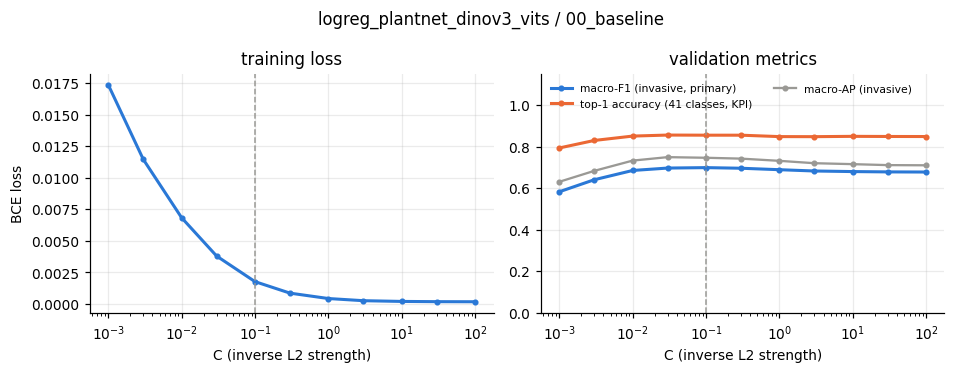

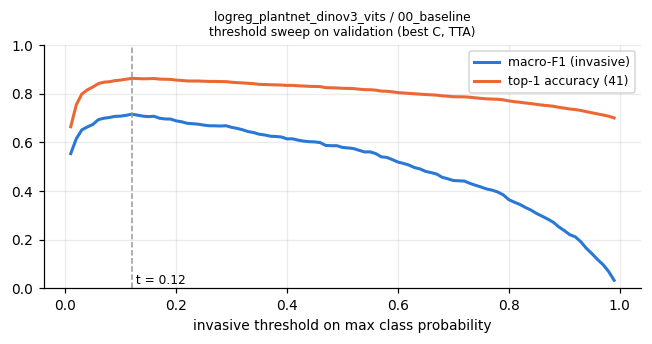

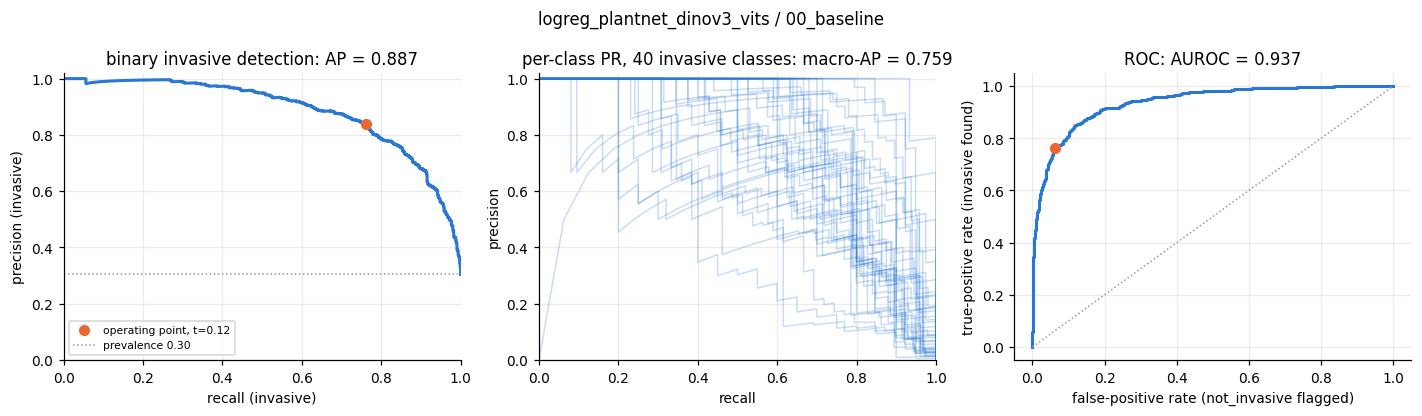

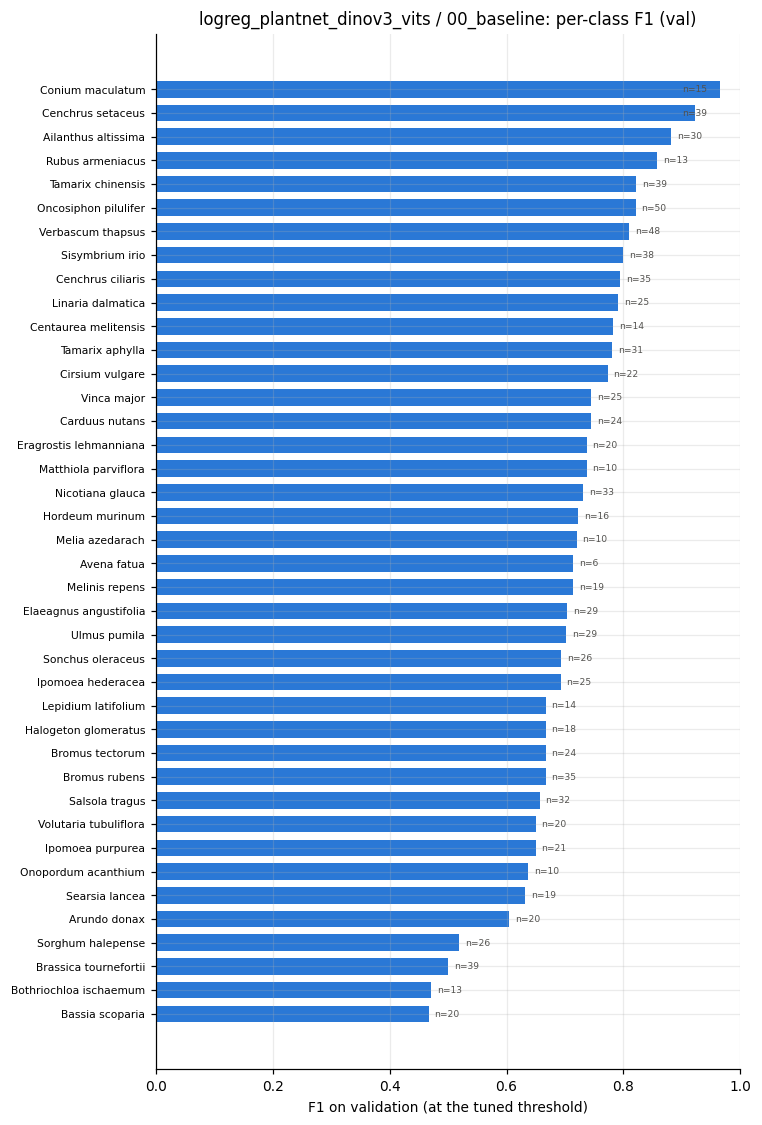

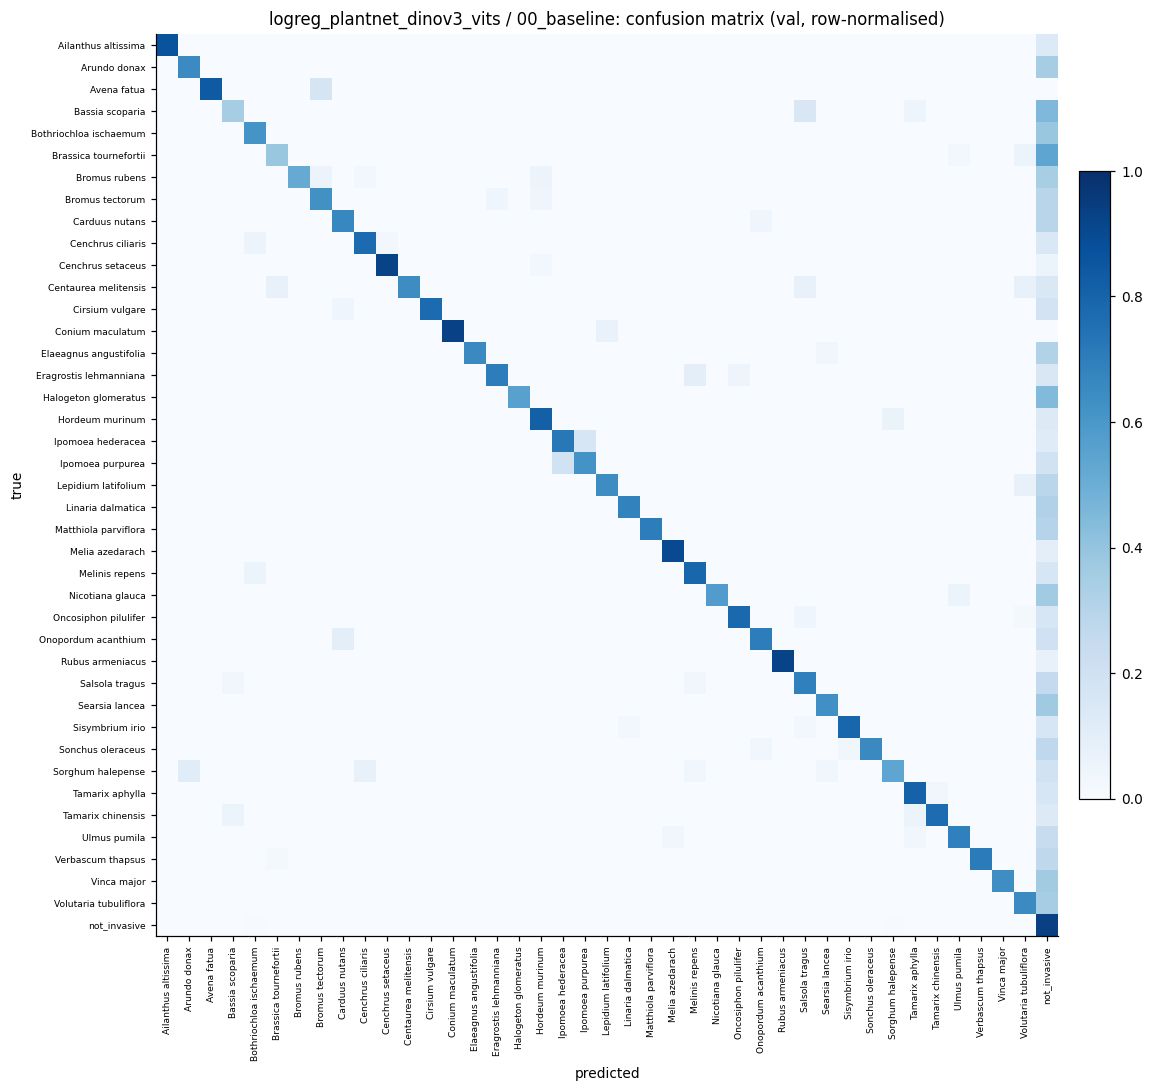

{'model': 'logreg_plantnet_dinov3_vits',
 'iteration': '00_baseline',
 'best_epoch': 5,
 'epochs': 11,
 'C': 0.1,
 'tta_hflip': True,
 'train_minutes': 39.02812008062998,
 'feature_minutes': 38.604863365491234,
 'macro_f1_invasive': 0.7152000665664673,
 'top1_acc_all': 0.8624535202980042,
 'macro_ap_invasive': 0.7590625205979085,
 'top1_recall_invasive': 0.8095723014256619,
 'top3_recall_invasive': 0.9409368635437881,
 'threshold': 0.12,
 'bin_precision_invasive': 0.8402699662542182,
 'bin_recall_invasive': 0.7606924643584522,
 'bin_f1_invasive': 0.7985034740780331,
 'bin_ap_invasive': np.float64(0.8874713171046287),
 'bin_auroc_invasive': np.float64(0.9372094857932545),
 'noninv_precision': 0.8995297135528003,
 'noninv_recall': 0.9367764915405165,
 'noninv_auroc': np.float64(0.9372094857932546),
 'macro_f1_all41': 0.7201409339904785}

In [ ]:
run_baseline("plantnet_dinov3_vits")


### DINOv3 ViT-S/16 (gated: needs the licence accepted on Hugging Face and the `HF_TOKEN` Colab secret)

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

===== logreg_dinov3_vits16 / 00_baseline -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/logreg_dinov3_vits16/00_baseline
backbone dinov3_vits16: 21.6M params (frozen), feat_dim 384 | DINOv3 ViT-S/16, ImageNet mean/std, pooling=cls


train features:   0%|          | 0/58 [00:00<?, ?batch/s]

val features:   0%|          | 0/26 [00:00<?, ?batch/s]

val features (mirrored):   0%|          | 0/26 [00:00<?, ?batch/s]

features: train (7342, 384), val (3228, 384) in 36.9 min
C   0.001 | train BCE 0.0167 | val macro-F1 0.5717 top1 0.8011 mAP 0.6246 t=0.03 | 3s
C   0.003 | train BCE 0.0113 | val macro-F1 0.6645 top1 0.8392 mAP 0.6920 t=0.07 | 3s
C    0.01 | train BCE 0.0069 | val macro-F1 0.7294 top1 0.8690 mAP 0.7590 t=0.11 | 2s
C    0.03 | train BCE 0.0039 | val macro-F1 0.7594 top1 0.8814 mAP 0.7902 t=0.14 | 2s
C     0.1 | train BCE 0.0019 | val macro-F1 0.7644 top1 0.8851 mAP 0.7988 t=0.15 | 2s
C     0.3 | train BCE 0.0009 | val macro-F1 0.7621 top1 0.8829 mAP 0.7999 t=0.11 | 2s
C       1 | train BCE 0.0005 | val macro-F1 0.7655 top1 0.8857 mAP 0.7959 t=0.15 | 2s
C       3 | train BCE 0.0003 | val macro-F1 0.7599 top1 0.8832 mAP 0.7892 t=0.15 | 3s
C      10 | train BCE 0.0002 | val macro-F1 0.7516 top1 0.8801 mAP 0.7859 t=0.16 | 2s
C      30 | train BCE 0.0002 | val macro-F1 0.7518 top1 0.8810 mAP 0.7843 t=0.16 | 2s
C     100 | train BCE 0.0002 | val macro-F1 0.7544 top1 0.8810 mAP 0.7833 t=0.16 | 

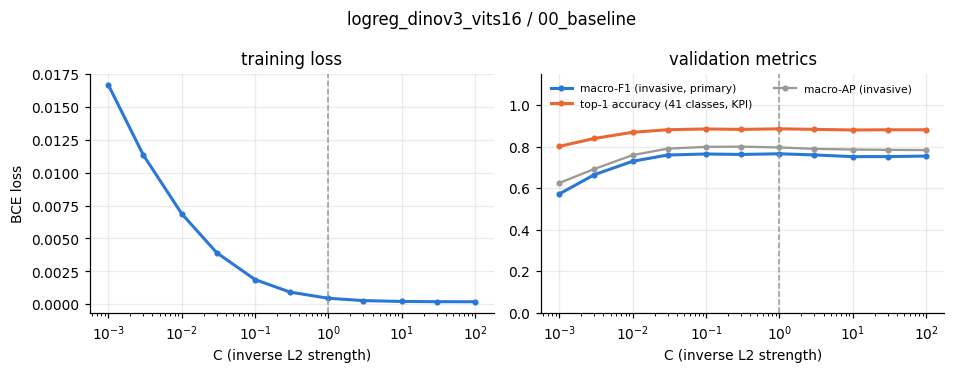

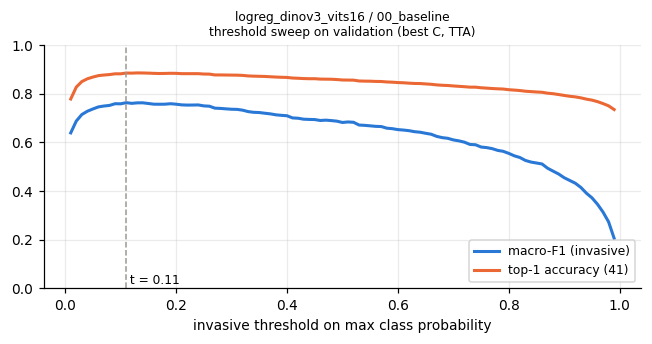

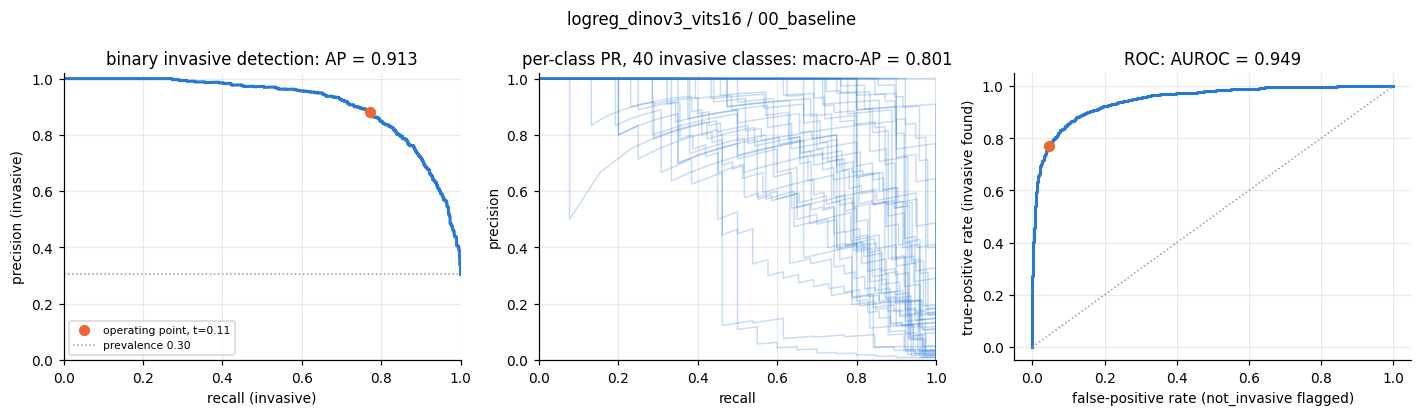

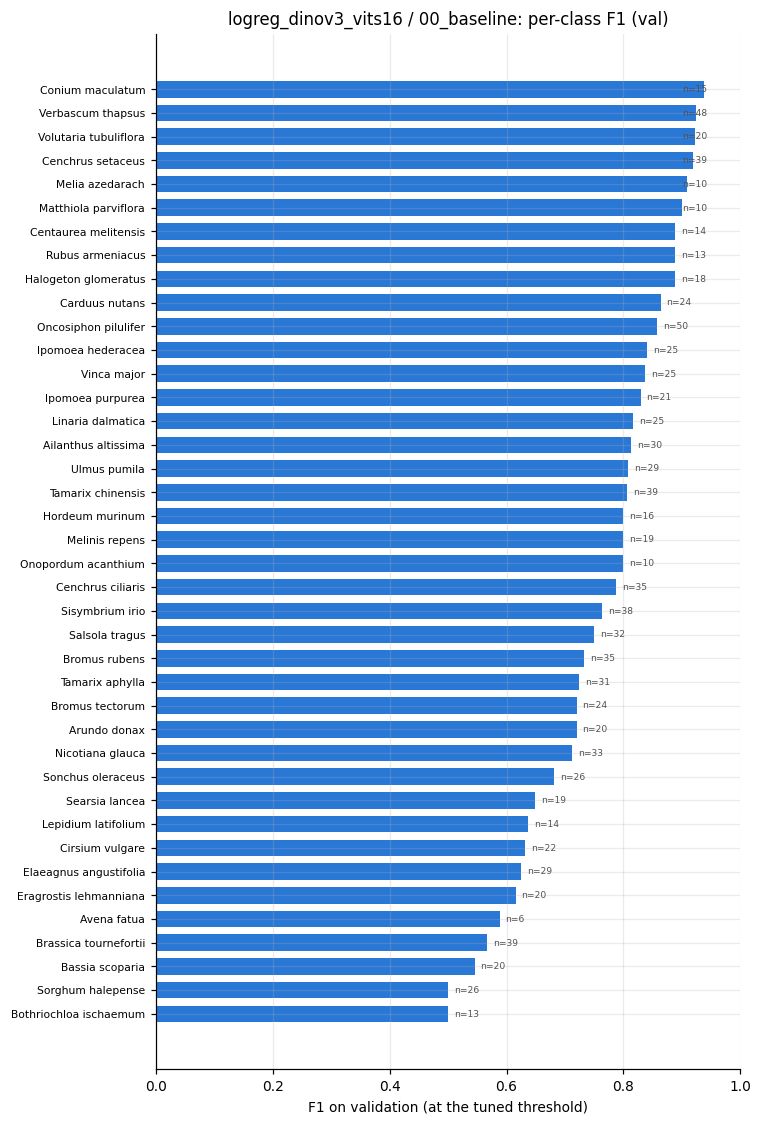

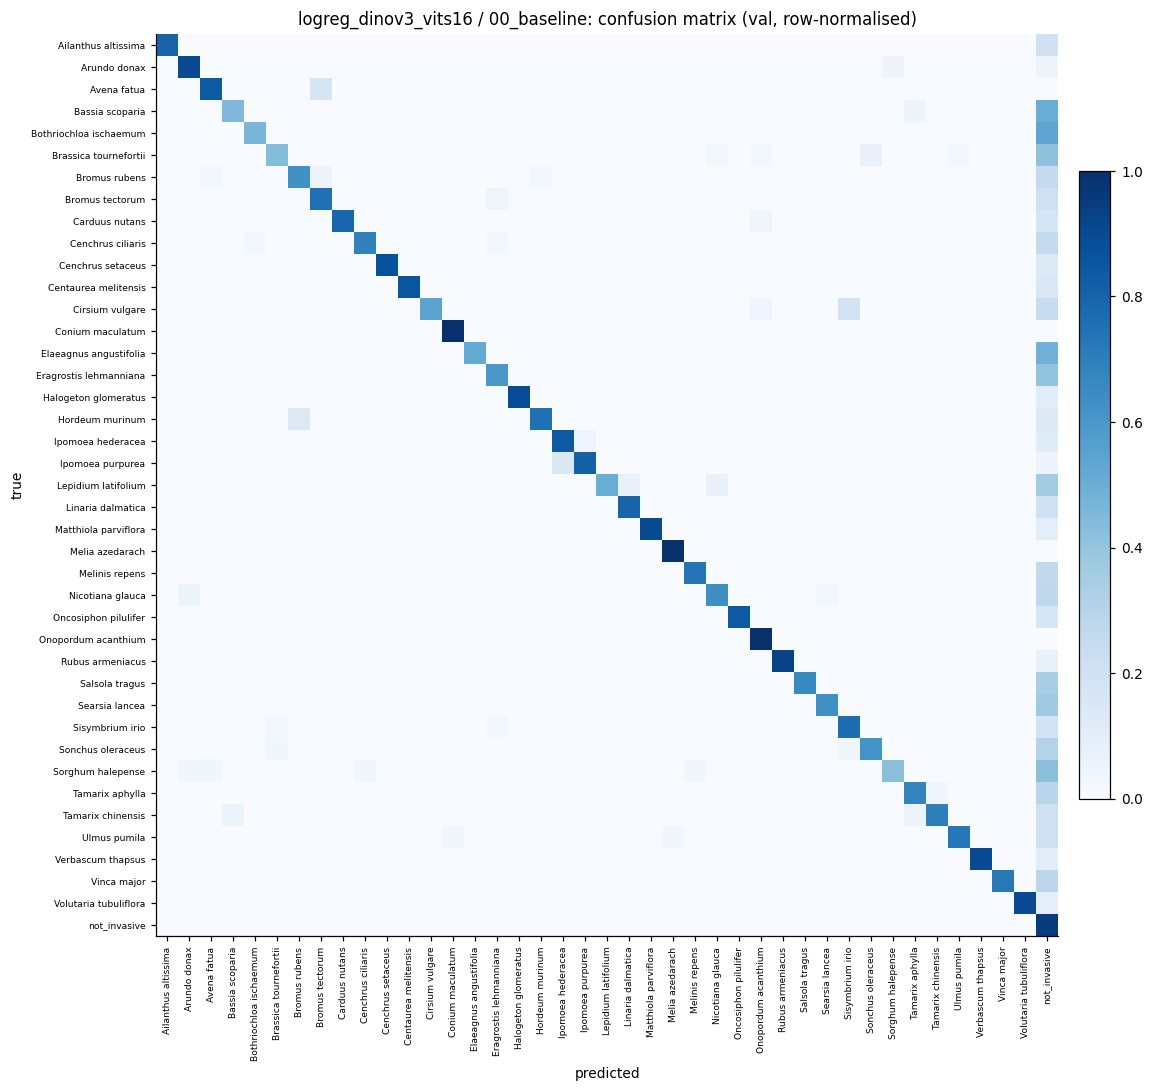

{'model': 'logreg_dinov3_vits16',
 'iteration': '00_baseline',
 'best_epoch': 7,
 'epochs': 11,
 'C': 1.0,
 'tta_hflip': True,
 'train_minutes': 37.343331476052605,
 'feature_minutes': 36.92654672066371,
 'macro_f1_invasive': 0.7624588012695312,
 'top1_acc_all': 0.8841387629508972,
 'macro_ap_invasive': 0.8010839913381634,
 'top1_recall_invasive': 0.829938900203666,
 'top3_recall_invasive': 0.9389002036659878,
 'threshold': 0.11,
 'bin_precision_invasive': 0.8813953488372093,
 'bin_recall_invasive': 0.7718940936863544,
 'bin_f1_invasive': 0.8230184581976113,
 'bin_ap_invasive': np.float64(0.9131688483183545),
 'bin_auroc_invasive': np.float64(0.9490372565484146),
 'noninv_precision': 0.9054054054054054,
 'noninv_recall': 0.9545859305431879,
 'noninv_auroc': np.float64(0.9490372565484148),
 'macro_f1_all41': 0.7665292024612427}

In [ ]:
run_baseline("dinov3_vits16")


### SigLIP 2 ViT-B/16

model.safetensors: reconstructing file:   0%|          |  0.00B /  372MB            

model.safetensors: downloading bytes:           |  0.00B            

===== logreg_siglip2_base / 00_baseline -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/logreg_siglip2_base/00_baseline
backbone siglip2_base: 92.9M params (frozen), feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0


train features:   0%|          | 0/58 [00:00<?, ?batch/s]

val features:   0%|          | 0/26 [00:00<?, ?batch/s]

val features (mirrored):   0%|          | 0/26 [00:00<?, ?batch/s]

features: train (7342, 768), val (3228, 768) in 206.4 min
C   0.001 | train BCE 0.0134 | val macro-F1 0.5430 top1 0.7754 mAP 0.5598 t=0.04 | 13s
C   0.003 | train BCE 0.0091 | val macro-F1 0.6309 top1 0.8231 mAP 0.6448 t=0.08 | 8s
C    0.01 | train BCE 0.0054 | val macro-F1 0.6699 top1 0.8473 mAP 0.7010 t=0.15 | 10s
C    0.03 | train BCE 0.0029 | val macro-F1 0.6820 top1 0.8544 mAP 0.7261 t=0.18 | 10s
C     0.1 | train BCE 0.0014 | val macro-F1 0.6908 top1 0.8563 mAP 0.7328 t=0.14 | 9s
C     0.3 | train BCE 0.0007 | val macro-F1 0.6845 top1 0.8525 mAP 0.7302 t=0.10 | 10s
C       1 | train BCE 0.0004 | val macro-F1 0.6737 top1 0.8467 mAP 0.7242 t=0.07 | 8s
C       3 | train BCE 0.0002 | val macro-F1 0.6708 top1 0.8479 mAP 0.7191 t=0.08 | 9s
C      10 | train BCE 0.0002 | val macro-F1 0.6702 top1 0.8470 mAP 0.7160 t=0.08 | 7s
C      30 | train BCE 0.0002 | val macro-F1 0.6689 top1 0.8467 mAP 0.7152 t=0.08 | 10s
C     100 | train BCE 0.0002 | val macro-F1 0.6694 top1 0.8470 mAP 0.7144 t=0

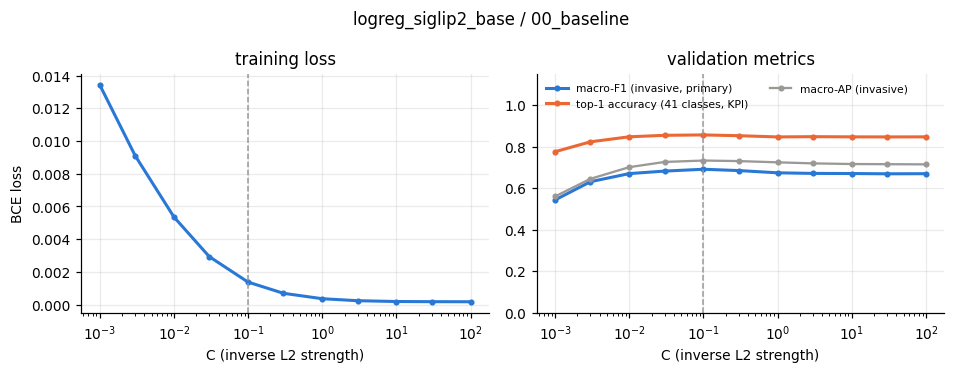

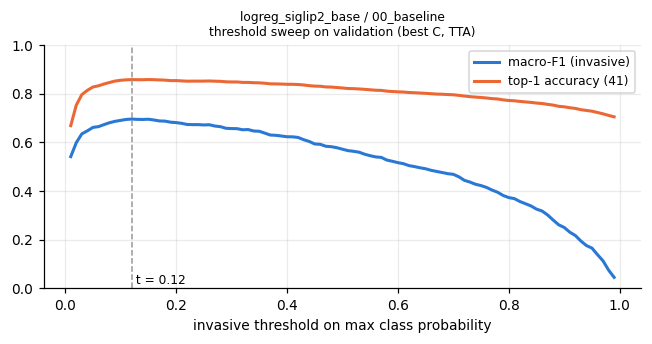

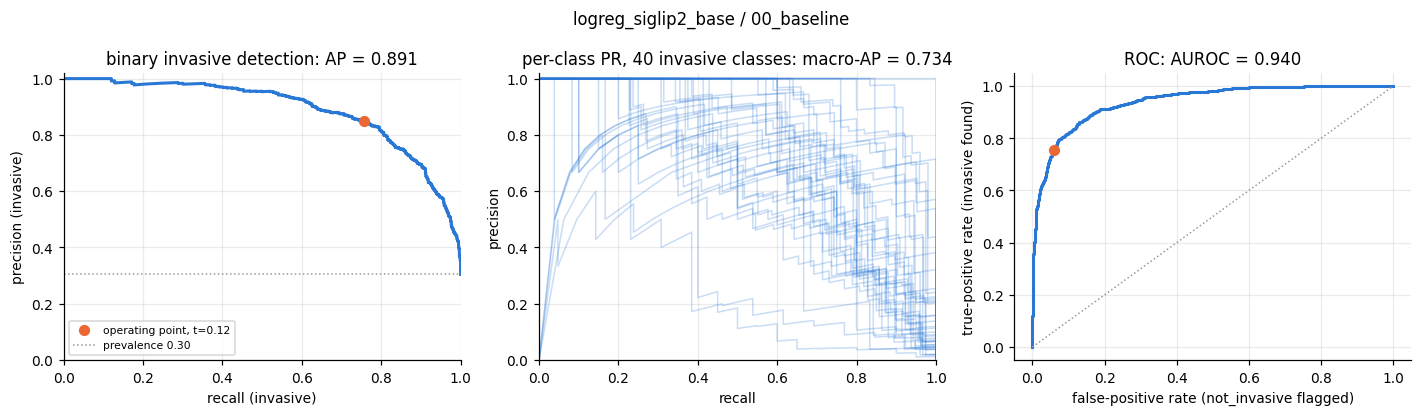

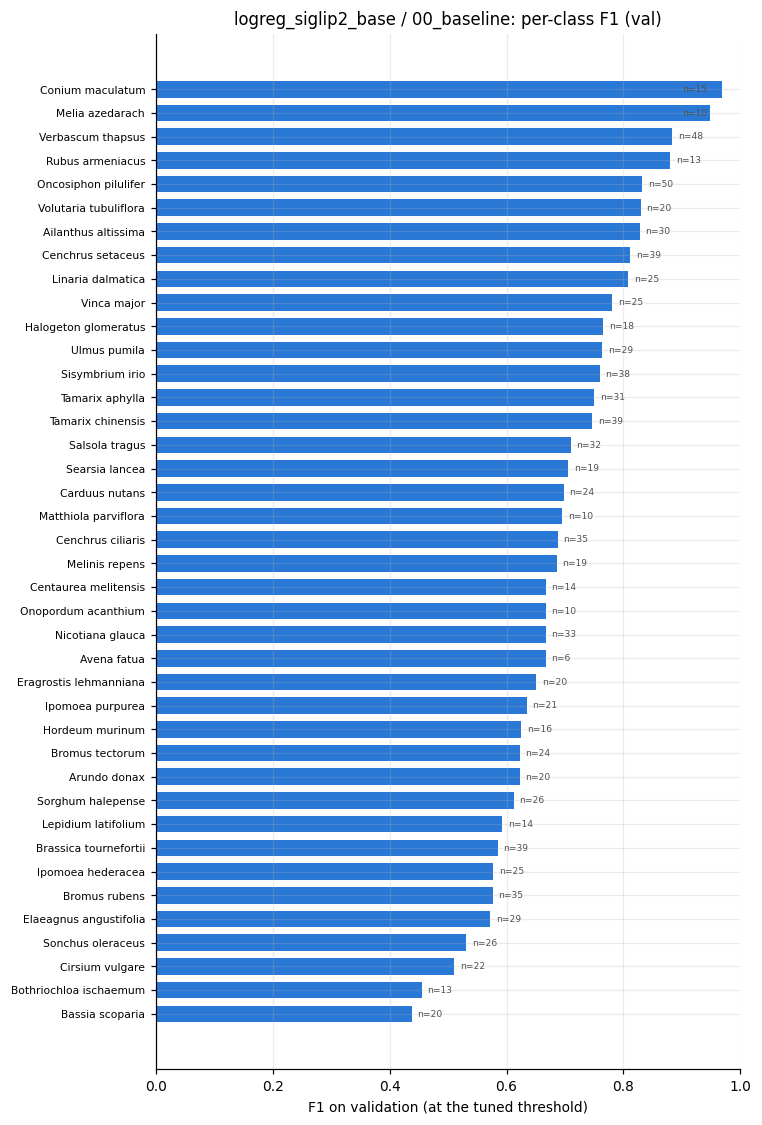

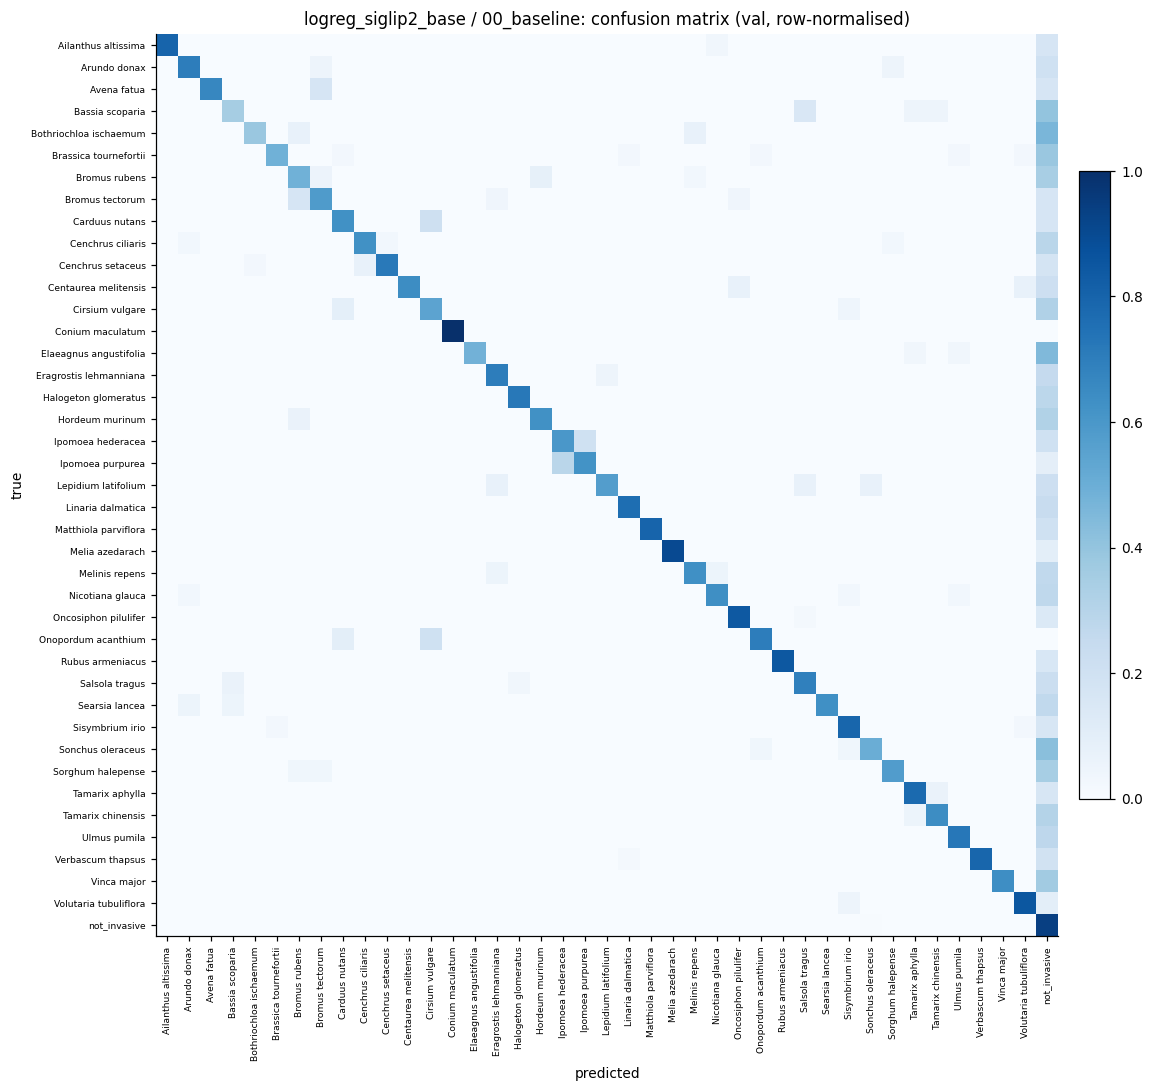

{'model': 'logreg_siglip2_base',
 'iteration': '00_baseline',
 'best_epoch': 5,
 'epochs': 11,
 'C': 0.1,
 'tta_hflip': True,
 'train_minutes': 208.07156460682552,
 'feature_minutes': 206.36672523419062,
 'macro_f1_invasive': 0.6950739622116089,
 'top1_acc_all': 0.8571870923042297,
 'macro_ap_invasive': 0.7343814835104077,
 'top1_recall_invasive': 0.7942973523421588,
 'top3_recall_invasive': 0.939918533604888,
 'threshold': 0.12,
 'bin_precision_invasive': 0.8481735159817352,
 'bin_recall_invasive': 0.7566191446028513,
 'bin_f1_invasive': 0.7997847147470398,
 'bin_ap_invasive': np.float64(0.8905197152057679),
 'bin_auroc_invasive': np.float64(0.9401892116874897),
 'noninv_precision': 0.8983843537414966,
 'noninv_recall': 0.9407836153161175,
 'noninv_auroc': np.float64(0.9401892116874896),
 'macro_f1_all41': 0.700537919998169}

In [ ]:
run_baseline("siglip2_base")


### ResNet50

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

===== logreg_resnet50 / 00_baseline -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/logreg_resnet50/00_baseline
backbone resnet50: 23.5M params (frozen), feat_dim 2048 | timm resnet50.a1_in1k, pool=SelectAdaptivePool2d(pool_type=avg, flatten=Flatten(start_dim=1, end_dim=-1)), drop_path=0.0


train features:   0%|          | 0/58 [00:00<?, ?batch/s]

val features:   0%|          | 0/26 [00:00<?, ?batch/s]

val features (mirrored):   0%|          | 0/26 [00:00<?, ?batch/s]

features: train (7342, 2048), val (3228, 2048) in 43.7 min
C   0.001 | train BCE 0.0145 | val macro-F1 0.2762 top1 0.6112 mAP 0.2606 t=0.02 | 13s
C   0.003 | train BCE 0.0090 | val macro-F1 0.3176 top1 0.6818 mAP 0.3026 t=0.04 | 15s
C    0.01 | train BCE 0.0043 | val macro-F1 0.3358 top1 0.6769 mAP 0.3279 t=0.04 | 14s
C    0.03 | train BCE 0.0020 | val macro-F1 0.3350 top1 0.6645 mAP 0.3301 t=0.03 | 13s
C     0.1 | train BCE 0.0008 | val macro-F1 0.3291 top1 0.6899 mAP 0.3218 t=0.03 | 13s
C     0.3 | train BCE 0.0004 | val macro-F1 0.3169 top1 0.6797 mAP 0.3077 t=0.02 | 12s
C       1 | train BCE 0.0002 | val macro-F1 0.3179 top1 0.6843 mAP 0.2956 t=0.02 | 11s
C       3 | train BCE 0.0001 | val macro-F1 0.3097 top1 0.6388 mAP 0.2870 t=0.01 | 11s
C      10 | train BCE 0.0001 | val macro-F1 0.3087 top1 0.6416 mAP 0.2843 t=0.01 | 11s
C      30 | train BCE 0.0001 | val macro-F1 0.3080 top1 0.6815 mAP 0.2832 t=0.02 | 11s
C     100 | train BCE 0.0001 | val macro-F1 0.3077 top1 0.6425 mAP 0.28

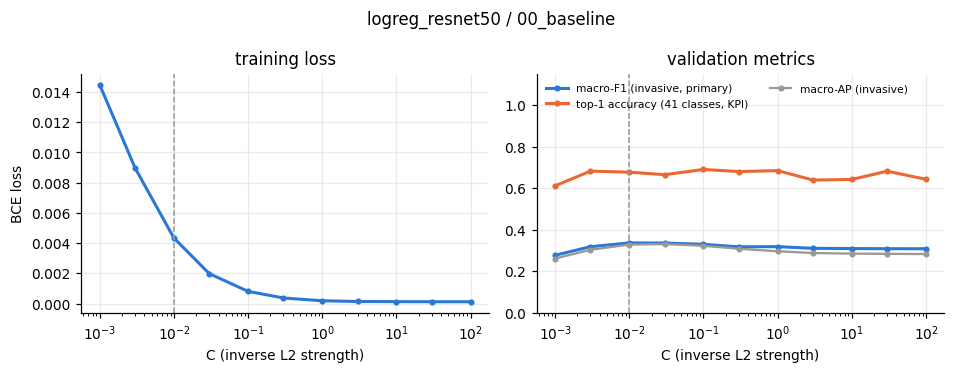

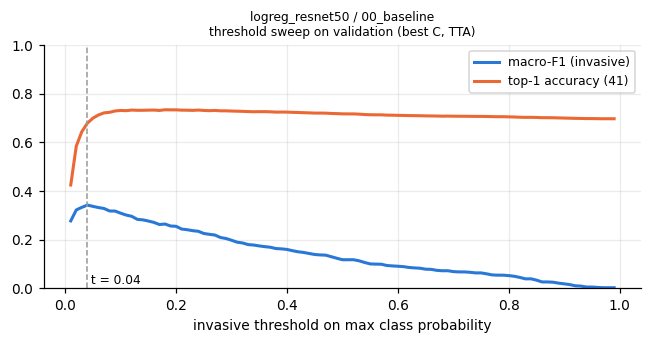

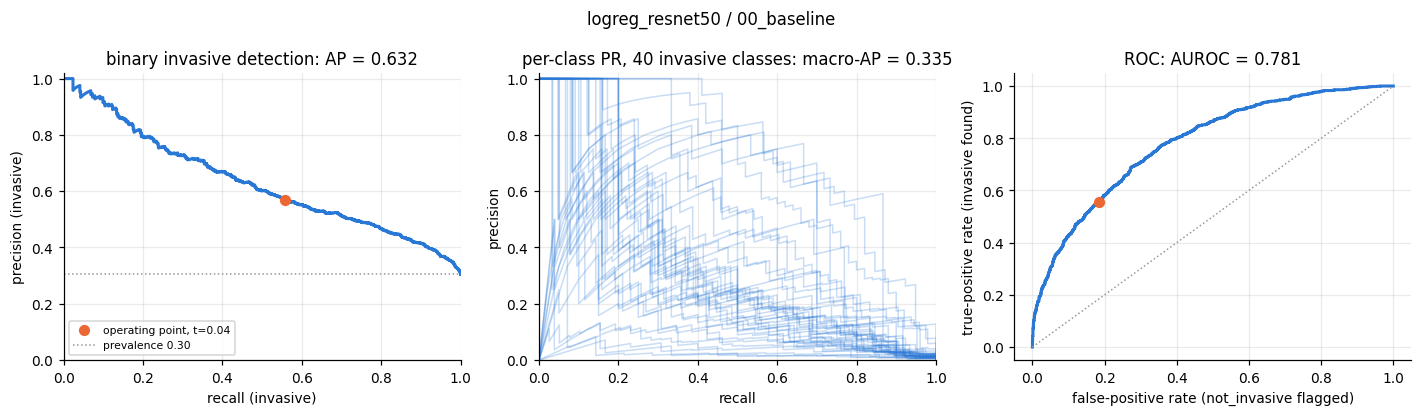

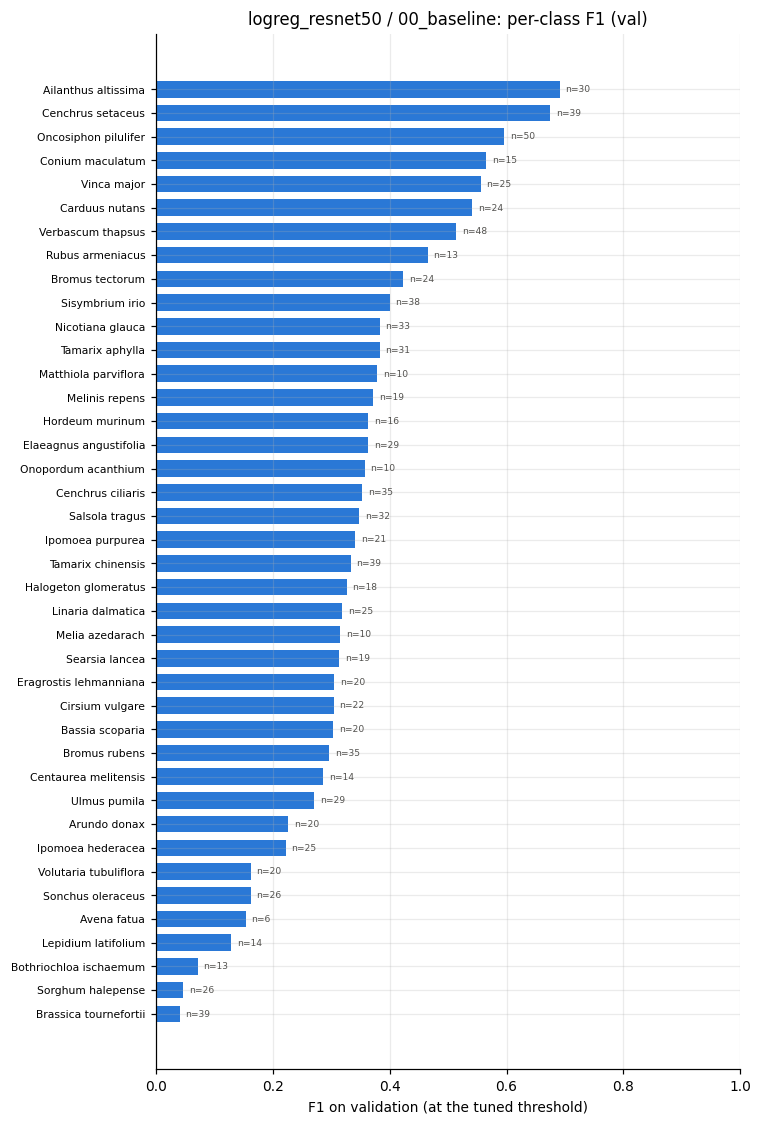

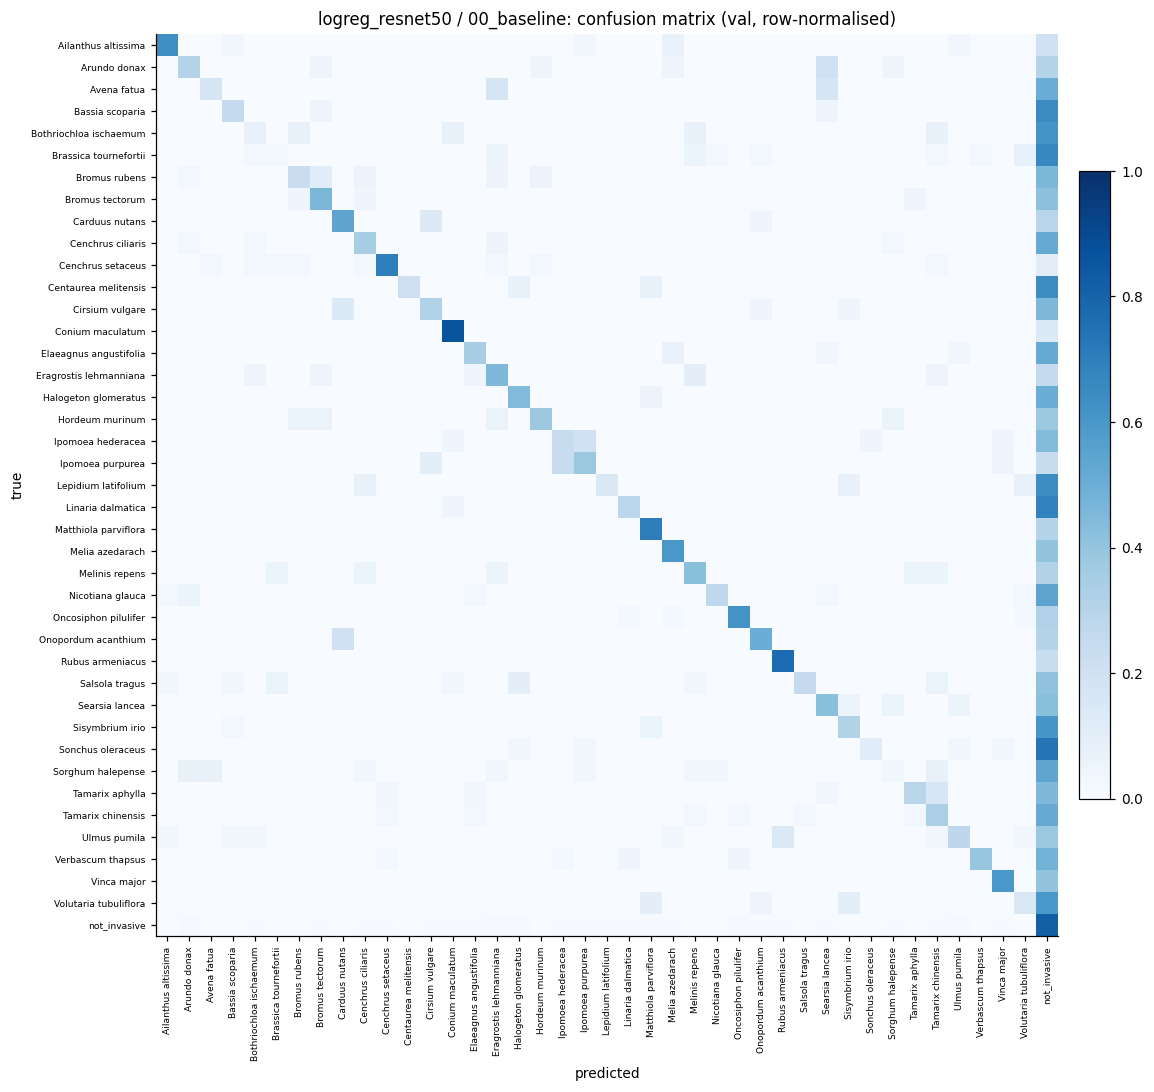

{'model': 'logreg_resnet50',
 'iteration': '00_baseline',
 'best_epoch': 3,
 'epochs': 11,
 'C': 0.01,
 'tta_hflip': True,
 'train_minutes': 46.006013464927676,
 'feature_minutes': 43.73820626735687,
 'macro_f1_invasive': 0.341401606798172,
 'top1_acc_all': 0.6781288981437683,
 'macro_ap_invasive': 0.334732632560841,
 'top1_recall_invasive': 0.49490835030549896,
 'top3_recall_invasive': 0.6995926680244399,
 'threshold': 0.04,
 'bin_precision_invasive': 0.5686070686070686,
 'bin_recall_invasive': 0.5570264765784114,
 'bin_f1_invasive': 0.5627572016460906,
 'bin_ap_invasive': np.float64(0.6321841600552227),
 'bin_auroc_invasive': np.float64(0.7813583052378249),
 'noninv_precision': 0.8080317740511915,
 'noninv_recall': 0.815227070347284,
 'noninv_auroc': np.float64(0.781358305237825),
 'macro_f1_all41': 0.3528701663017273}

In [ ]:
run_baseline("resnet50")


### ConvNeXt-Tiny

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

===== logreg_convnext_tiny / 00_baseline -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/logreg_convnext_tiny/00_baseline
backbone convnext_tiny: 27.8M params (frozen), feat_dim 768 | timm convnext_tiny.fb_in22k_ft_in1k, pool=?, drop_path=0.0


train features:   0%|          | 0/58 [00:00<?, ?batch/s]

val features:   0%|          | 0/26 [00:00<?, ?batch/s]

val features (mirrored):   0%|          | 0/26 [00:00<?, ?batch/s]

features: train (7342, 768), val (3228, 768) in 36.3 min
C   0.001 | train BCE 0.0141 | val macro-F1 0.5368 top1 0.7797 mAP 0.5768 t=0.03 | 6s
C   0.003 | train BCE 0.0088 | val macro-F1 0.6102 top1 0.8191 mAP 0.6373 t=0.07 | 3s
C    0.01 | train BCE 0.0046 | val macro-F1 0.6503 top1 0.8395 mAP 0.6780 t=0.11 | 6s
C    0.03 | train BCE 0.0023 | val macro-F1 0.6611 top1 0.8420 mAP 0.6948 t=0.10 | 5s
C     0.1 | train BCE 0.0010 | val macro-F1 0.6681 top1 0.8467 mAP 0.7032 t=0.08 | 3s
C     0.3 | train BCE 0.0005 | val macro-F1 0.6714 top1 0.8467 mAP 0.7030 t=0.07 | 3s
C       1 | train BCE 0.0003 | val macro-F1 0.6666 top1 0.8445 mAP 0.6989 t=0.07 | 4s
C       3 | train BCE 0.0002 | val macro-F1 0.6634 top1 0.8429 mAP 0.6947 t=0.06 | 3s
C      10 | train BCE 0.0002 | val macro-F1 0.6647 top1 0.8467 mAP 0.6925 t=0.10 | 3s
C      30 | train BCE 0.0002 | val macro-F1 0.6633 top1 0.8432 mAP 0.6918 t=0.07 | 3s
C     100 | train BCE 0.0002 | val macro-F1 0.6627 top1 0.8426 mAP 0.6919 t=0.07 | 

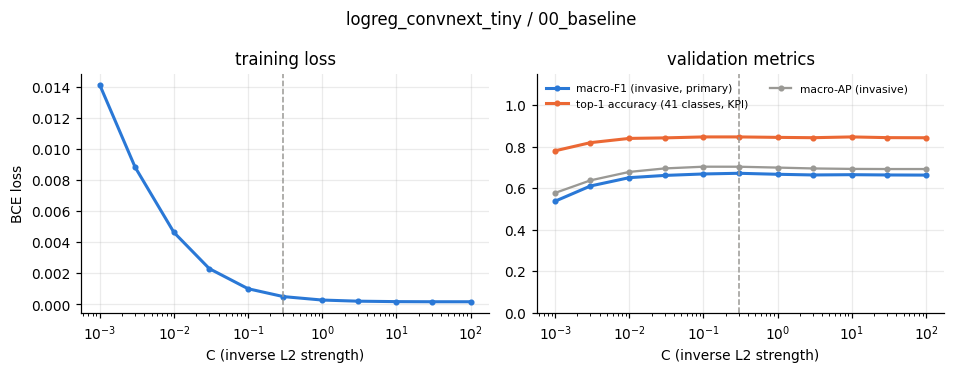

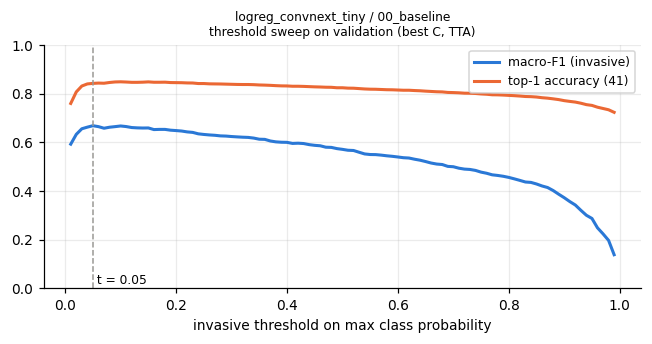

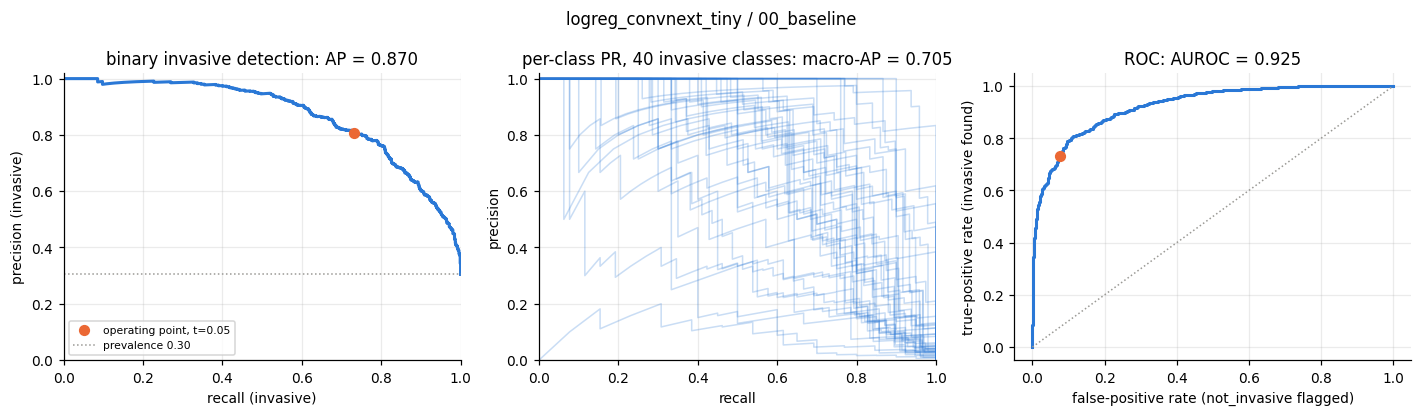

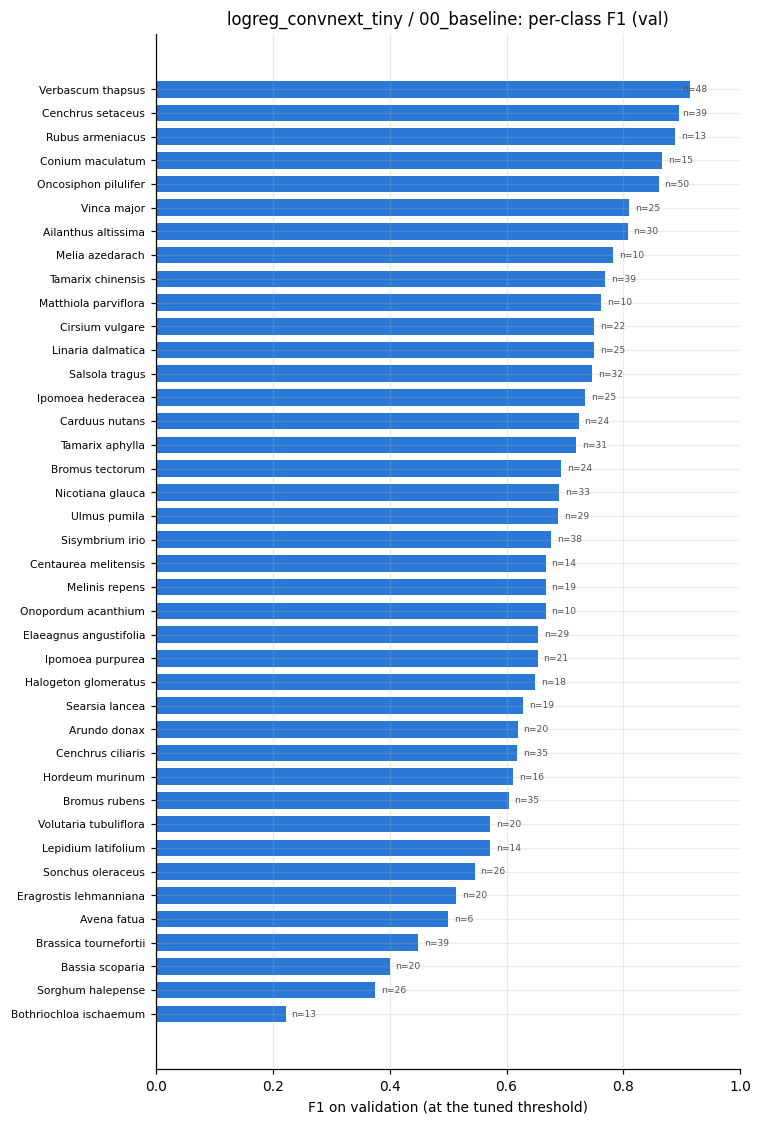

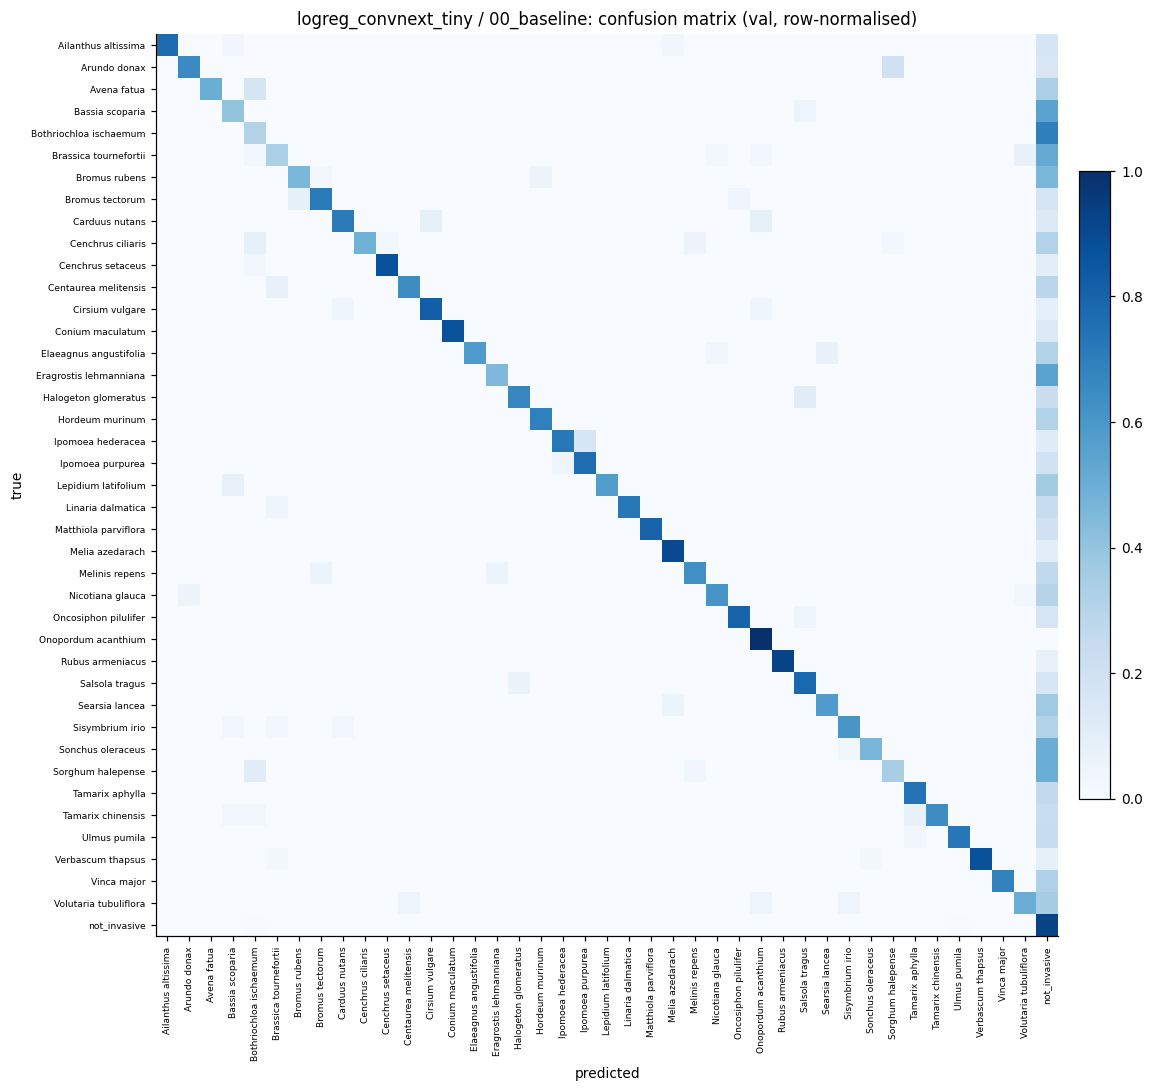

{'model': 'logreg_convnext_tiny',
 'iteration': '00_baseline',
 'best_epoch': 6,
 'epochs': 11,
 'C': 0.3,
 'tta_hflip': True,
 'train_minutes': 37.11562227408091,
 'feature_minutes': 36.34647835890452,
 'macro_f1_invasive': 0.6677454710006714,
 'top1_acc_all': 0.841697633266449,
 'macro_ap_invasive': 0.7046090963041352,
 'top1_recall_invasive': 0.7708757637474541,
 'top3_recall_invasive': 0.9012219959266803,
 'threshold': 0.05,
 'bin_precision_invasive': 0.8069584736251403,
 'bin_recall_invasive': 0.7321792260692465,
 'bin_f1_invasive': 0.7677522690870262,
 'bin_ap_invasive': np.float64(0.8697717975313164),
 'bin_auroc_invasive': np.float64(0.9248752704513841),
 'noninv_precision': 0.8874625588361147,
 'noninv_recall': 0.9234194122885129,
 'noninv_auroc': np.float64(0.924875270451384),
 'macro_f1_all41': 0.6735342741012573}

In [ ]:
run_baseline("convnext_tiny")
